# **Project Name**    - Flight Price Prediction (Travel MLOps Capstone)

##### **Project Type**    - Regression
##### **Contribution**    - Individual
##### **Team Member 1 -**

# **Project Summary -**

In this project I worked with a travel dataset made of three tables: users, flights and hotels. This notebook covers the first part of the capstone, which is a regression model that predicts the price of a flight. The same model is later served through a Flask API, packaged in a Docker image, deployed on Kubernetes, retrained by an Airflow DAG, deployed through a Jenkins pipeline and tracked in MLflow. Those parts are in the GitHub repo, and here I focus on the data and the model.

The flights table has 271,888 bookings between September 2019 and July 2023, with ten columns including origin, destination, flight class, agency, distance, flight time and price. There were no missing values or duplicate rows, so most of my wrangling went into understanding how the data is built. Every travel code is an outbound flight on a Thursday plus a return flight a few days later. There are 9 cities, and 70 of the 72 possible routes are flown (Rio de Janeiro and Salvador are never connected). The key finding came early: the price is fixed for a given route, class and agency. There are 490 such combinations and exactly 490 unique prices, so the date of the flight and the person who booked it have no effect on the fare.

My 15 charts (univariate, bivariate and multivariate) showed that first class makes up 42.8% of bookings, that FlyingDrops only sells first class tickets, that price grows with distance at a rate that depends on the class (about 0.75 per km for economy and 1.37 per km for first class), and that the two directions of a route differ in price by 23.5% on average. Booking volume has been falling every year since late 2019 while the average price stayed flat at around 950 to 960. Two companies, Acme Factory and Umbrella LTDA, pay more per flight, but only because their employees fly longer routes.

I tested three hypotheses. First class is more expensive than economy (Welch t-test, p close to 0). FlyingDrops looks about 29% more expensive, but comparing first class tickets on the same routes with a Friedman test gave p = 0.94, so there is no real agency premium. The date has a Spearman correlation of only 0.0075 with price, which counts as significant only because of the huge sample.

For the model I used six inputs: from, to, flightType, agency, distance and time. The categorical columns are one-hot encoded inside a scikit-learn pipeline, so the same steps run in training and in the API. Permutation importance confirmed that year, month and weekday add nothing. I trained Linear Regression, Random Forest and HistGradientBoosting and tuned each one with cross validation. Linear regression reached an R2 of 0.919 with an RMSE of 103. The random forest predicted the test set perfectly and tuned gradient boosting was almost the same (RMSE 0.004). These scores are not leakage, they come from the price being a lookup of route, class and agency.

As a harder test, I ran a GroupKFold that holds out whole routes. Here the ranking flips: linear regression keeps an R2 of 0.84 while the tuned random forest drops to 0.71. So the forest is the right model for the routes the company already flies, which is what the API serves, but a new route needs retraining, which is the job of the Airflow pipeline. The final model is the tuned random forest, saved with joblib together with a route lookup table so the API only needs the origin, destination, class and agency.

# **GitHub Link -**

https://github.com/Tahascommit/travel-mlops-capstone

# **Problem Statement**


A travel company sells flight tickets from several agencies on a network of nine cities in Brazil. Customers and the booking team want to know what a ticket will cost before booking it, and right now there is no quick and consistent way to get a price for a given route, class and agency.

The aim of this notebook is to build a regression model that predicts the price of a flight from the trip details: origin, destination, flight class and agency, plus the distance and flight time of the route. The model should be accurate, easy to explain and ready to be served in real time through a REST API.

**Business objective:** give the booking platform an instant and reliable price estimate for any flight on the existing route network. Customers can then compare classes and agencies quickly, the sales team can quote prices without looking them up by hand, and the model can be retrained automatically as new booking data comes in.

# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required. 
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits. 
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule. 

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries
import os
import hashlib
import urllib.request
import warnings
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import (train_test_split, KFold, GroupKFold,
                                     GridSearchCV, RandomizedSearchCV, cross_validate)
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                             mean_absolute_percentage_error)
from sklearn.inspection import permutation_importance
import joblib

# shap is only used for explainability at the end. colab may not have it, so install if missing
try:
    import shap
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "shap"])
    import shap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

### Dataset Loading

In [2]:
# Load Dataset
# inside the repo we read the local csv files, on colab they are read straight from github
DATA_PATH = "../data/raw/" if os.path.exists("../data/raw/flights.csv") else "https://raw.githubusercontent.com/Tahascommit/travel-mlops-capstone/main/data/raw/"

try:
    flights = pd.read_csv(DATA_PATH + "flights.csv")
    users = pd.read_csv(DATA_PATH + "users.csv")   # only used for a few EDA charts
except Exception as e:
    raise RuntimeError(f"Could not load the data from {DATA_PATH}: {e}")

print("Data loaded from:", DATA_PATH)

Data loaded from: ../data/raw/


### Dataset First View

In [3]:
# Dataset First Look
flights.head(10)

,travelCode,userCode,from,to,flightType,price,time,distance,agency,date
0,0,0,Recife (PE),Florianopolis (SC),firstClass,1434.38,1.76,676.53,FlyingDrops,09/26/2019
1,0,0,Florianopolis (SC),Recife (PE),firstClass,1292.29,1.76,676.53,FlyingDrops,09/30/2019
2,1,0,Brasilia (DF),Florianopolis (SC),firstClass,1487.52,1.66,637.56,CloudFy,10/03/2019
3,1,0,Florianopolis (SC),Brasilia (DF),firstClass,1127.36,1.66,637.56,CloudFy,10/04/2019
4,2,0,Aracaju (SE),Salvador (BH),firstClass,1684.05,2.16,830.86,CloudFy,10/10/2019
5,2,0,Salvador (BH),Aracaju (SE),firstClass,1531.92,2.16,830.86,CloudFy,10/12/2019
6,3,0,Aracaju (SE),Campo Grande (MS),economic,743.54,1.69,650.10,Rainbow,10/17/2019
7,3,0,Campo Grande (MS),Aracaju (SE),economic,877.56,1.69,650.10,Rainbow,10/20/2019
8,4,0,Recife (PE),Florianopolis (SC),economic,803.39,1.76,676.53,Rainbow,10/24/2019
9,4,0,Florianopolis (SC),Recife (PE),economic,695.30,1.76,676.53,Rainbow,10/26/2019


In [4]:
# users table, joined later on userCode for a couple of charts
users.head()

,code,company,name,gender,age
0,0,4You,Roy Braun,male,21
1,1,4You,Joseph Holsten,male,37
2,2,4You,Wilma Mcinnis,female,48
3,3,4You,Paula Daniel,female,23
4,4,4You,Patricia Carson,female,44


### Dataset Rows & Columns count

In [5]:
# Dataset Rows & Columns count
print("flights.csv ->", flights.shape[0], "rows and", flights.shape[1], "columns")
print("users.csv   ->", users.shape[0], "rows and", users.shape[1], "columns")

flights.csv -> 271888 rows and 10 columns
users.csv   -> 1340 rows and 5 columns


### Dataset Information

In [6]:
# Dataset Info
flights.info()

<class 'pandas.DataFrame'>
RangeIndex: 271888 entries, 0 to 271887
Data columns (total 10 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   travelCode  271888 non-null  int64  
 1   userCode    271888 non-null  int64  
 2   from        271888 non-null  str    
 3   to          271888 non-null  str    
 4   flightType  271888 non-null  str    
 5   price       271888 non-null  float64
 6   time        271888 non-null  float64
 7   distance    271888 non-null  float64
 8   agency      271888 non-null  str    
 9   date        271888 non-null  str    
dtypes: float64(3), int64(2), str(5)
memory usage: 35.0 MB


#### Duplicate Values

In [7]:
# Dataset Duplicate Value Count
print("Duplicate rows in flights:", flights.duplicated().sum())
# same flight details for the same travel would also be a duplicate even if the date differs
print("Duplicate (travelCode, from, to) rows:", flights.duplicated(subset=["travelCode", "from", "to"]).sum())

Duplicate rows in flights: 0
Duplicate (travelCode, from, to) rows: 0


#### Missing Values/Null Values

In [8]:
# Missing Values/Null Values Count
flights.isnull().sum()

travelCode    0
userCode      0
from          0
to            0
flightType    0
price         0
time          0
distance      0
agency        0
date          0
dtype: int64

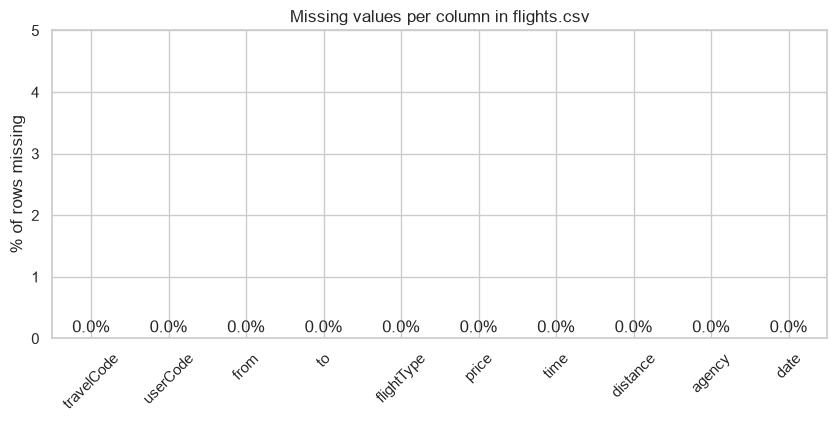

In [9]:
# Visualizing the missing values
missing_pct = flights.isnull().mean() * 100
ax = missing_pct.plot(kind="bar", color="steelblue", figsize=(10, 4))
ax.set_ylim(0, 5)
ax.set_ylabel("% of rows missing")
ax.set_title("Missing values per column in flights.csv")
for i, v in enumerate(missing_pct):
    ax.text(i, v + 0.1, f"{v:.1f}%", ha="center")
plt.xticks(rotation=45)
plt.show()

### What did you know about your dataset?

The flights dataset has 271,888 rows and 10 columns, and each row is one flight booking. Three columns are numeric (price, time and distance), two are IDs (travelCode and userCode), and the rest are text: origin city, destination city, flight class, agency and the date, which is stored as a string. There are no missing values and no duplicate rows, so the data is already clean.

The users table has 1,340 users and I only use it for a few charts (company, gender and age).

A few things stood out at this stage. Price goes from 301.51 to 1,754.17 but has only 490 unique values, and distance and time have only 35 and 33 unique values. That already hints that these values are fixed per route instead of changing from booking to booking.

## ***2. Understanding Your Variables***

In [10]:
# Dataset Columns
flights.columns.tolist()

['travelCode',
 'userCode',
 'from',
 'to',
 'flightType',
 'price',
 'time',
 'distance',
 'agency',
 'date']

In [11]:
# Dataset Describe
flights.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
travelCode,271888.0,NaN,NaN,NaN,67971.5,39243.724665,0.0,33985.75,67971.5,101957.25,135943.0
userCode,271888.0,NaN,NaN,NaN,667.505495,389.523127,0.0,326.0,659.0,1011.0,1339.0
from,271888,9,Florianopolis (SC),57317,NaN,NaN,NaN,NaN,NaN,NaN,NaN
to,271888,9,Florianopolis (SC),57317,NaN,NaN,NaN,NaN,NaN,NaN,NaN
flightType,271888,3,firstClass,116418,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,271888.0,NaN,NaN,NaN,957.37503,362.31189,301.51,672.66,904.0,1222.24,1754.17
time,271888.0,NaN,NaN,NaN,1.421147,0.542541,0.44,1.04,1.46,1.76,2.44
distance,271888.0,NaN,NaN,NaN,546.955535,208.851288,168.22,401.66,562.14,676.53,937.77
agency,271888,3,Rainbow,116752,NaN,NaN,NaN,NaN,NaN,NaN,NaN
date,271888,999,09/26/2019,1335,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Variables Description 

* **travelCode** : id of a trip. Each trip has two rows, the outbound flight and the return flight.
* **userCode** : id of the user who booked the trip, it links to `code` in users.csv.
* **from** : origin city with its state code, for example "Recife (PE)". There are 9 cities.
* **to** : destination city, the same 9 cities.
* **flightType** : class of the ticket, one of economic, premium or firstClass.
* **price** : price of the ticket. This is the target variable.
* **time** : flight duration in hours (0.44 to 2.44).
* **distance** : distance of the route in km (168.22 to 937.77).
* **agency** : agency that sold the ticket, one of CloudFy, Rainbow or FlyingDrops.
* **date** : date of the flight in mm/dd/yyyy format.

### Check Unique Values for each variable.

In [12]:
# Check Unique Values for each variable.
for col in flights.columns:
    print(f"{col:<12} -> {flights[col].nunique()} unique values")

travelCode   -> 135944 unique values
userCode     -> 1335 unique values
from         -> 9 unique values
to           -> 9 unique values
flightType   -> 3 unique values
price        -> 490 unique values
time         -> 33 unique values
distance     -> 35 unique values
agency       -> 3 unique values
date         -> 999 unique values


## 3. ***Data Wrangling***

### Data Wrangling Code

In [13]:
# Write your code to make your dataset analysis ready.
df = flights.copy()

# date comes as a mm/dd/yyyy string, convert it so we can pull out year, month and weekday
df["date"] = pd.to_datetime(df["date"], format="%m/%d/%Y")
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day_of_week"] = df["date"].dt.day_name()

# one route column is easier to group on than from + to
df["route"] = df["from"] + " -> " + df["to"]

# price per km is only for analysis. it is built from the target so it can't be a model feature
df["price_per_km"] = df["price"] / df["distance"]

# join the user details (company, gender, age) for a few charts
user_info = users.rename(columns={"code": "userCode", "name": "user_name"})
df = df.merge(user_info, on="userCode", how="left")
df["age_group"] = pd.cut(df["age"], bins=[20, 30, 40, 50, 60, 70],
                         labels=["21-30", "31-40", "41-50", "51-60", "61-65"])

print("Shape after wrangling:", df.shape)
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
df.head()

Shape after wrangling: (271888, 20)
Date range: 2019-09-26 to 2023-07-24


,travelCode,userCode,from,to,flightType,price,time,distance,agency,date,year,month,day_of_week,route,price_per_km,company,user_name,gender,age,age_group
0,0,0,Recife (PE),Florianopolis (SC),firstClass,1434.38,1.76,676.53,FlyingDrops,2019-09-26,2019,9,Thursday,Recife (PE) -> Florianopolis (SC),2.120202,4You,Roy Braun,male,21,21-30
1,0,0,Florianopolis (SC),Recife (PE),firstClass,1292.29,1.76,676.53,FlyingDrops,2019-09-30,2019,9,Monday,Florianopolis (SC) -> Recife (PE),1.910174,4You,Roy Braun,male,21,21-30
2,1,0,Brasilia (DF),Florianopolis (SC),firstClass,1487.52,1.66,637.56,CloudFy,2019-10-03,2019,10,Thursday,Brasilia (DF) -> Florianopolis (SC),2.333145,4You,Roy Braun,male,21,21-30
3,1,0,Florianopolis (SC),Brasilia (DF),firstClass,1127.36,1.66,637.56,CloudFy,2019-10-04,2019,10,Friday,Florianopolis (SC) -> Brasilia (DF),1.768241,4You,Roy Braun,male,21,21-30
4,2,0,Aracaju (SE),Salvador (BH),firstClass,1684.05,2.16,830.86,CloudFy,2019-10-10,2019,10,Thursday,Aracaju (SE) -> Salvador (BH),2.026876,4You,Roy Braun,male,21,21-30


In [14]:
# every travelCode should have an outbound and a return flight
print("Flights per travelCode:")
print(df.groupby("travelCode").size().value_counts())

# which routes exist?
cities = sorted(df["from"].unique())
all_pairs = {(a, b) for a in cities for b in cities if a != b}
present = set(zip(df["from"], df["to"]))
print("\nCities:", len(cities))
print("Routes in the data:", len(present), "out of", len(all_pairs), "possible")
print("Routes never flown:", sorted(all_pairs - present))

Flights per travelCode:
2    135944
Name: count, dtype: int64



Cities:

 9
Routes in the data: 70 out of 72 possible
Routes never flown: [('Rio de Janeiro (RJ)', 'Salvador (BH)'), ('Salvador (BH)', 'Rio de Janeiro (RJ)')]


In [15]:
# is the price fixed for a given route + class + agency?
combo = df.groupby(["from", "to", "flightType", "agency"])["price"]
print("Route / class / agency combinations:", combo.ngroups)
print("Max number of different prices inside one combination:", combo.nunique().max())
print("Unique prices in the whole dataset:", df["price"].nunique())

Route / class / agency combinations: 490
Max number of different prices inside one combination: 1
Unique prices in the whole dataset: 490


In [16]:
# which agency sells which class
pd.crosstab(df["agency"], df["flightType"], margins=True)

flightType,economic,firstClass,premium,All
agency,,,,
CloudFy,38656,38862,38860,116378
FlyingDrops,0,38758,0,38758
Rainbow,38810,38798,39144,116752
All,77466,116418,78004,271888


In [17]:
# average price by class and agency
df.groupby(["flightType", "agency"])["price"].agg(["count", "mean", "median", "min", "max"]).round(2)

count     mean   median     min      max
flightType agency                                               
economic   CloudFy      38656   658.89   674.52  301.51   972.12
           Rainbow      38810   658.00   674.16  301.61   959.79
firstClass CloudFy      38862  1180.29  1244.73  563.00  1747.31
           FlyingDrops  38758  1186.16  1269.73  539.39  1744.87
           Rainbow      38798  1176.76  1181.19  549.55  1754.17
premium    CloudFy      38860   916.13   918.66  447.53  1370.17
           Rainbow      39144   924.62   962.54  427.25  1367.88

In [18]:
# on which weekdays do people fly?
df["day_of_week"].value_counts()

day_of_week
Thursday    135944
Monday       34108
Sunday       34088
Friday       33880
Saturday     33868
Name: count, dtype: int64

### What all manipulations have you done and insights you found?

What I did:

* converted `date` from text to a real date and pulled out the year, month and day of the week
* created a `route` column ("from -> to") to make grouping easier. I also use it later as the group in GroupKFold
* created `price_per_km` for analysis only. It is built from the target, so it is never given to the model
* joined users.csv on userCode to get company, gender and age, and grouped age into five bands

What I found:

* the data covers flights from 2019-09-26 to 2023-07-24
* every travelCode has exactly 2 flights, so each trip is an outbound + return pair
* there are 9 cities and 70 of the 72 possible routes. Rio de Janeiro to Salvador (and back) is never flown
* there are 490 route/class/agency combinations and 490 unique prices, and no combination has more than one price. So the price is fully decided by route, class and agency, and the date or the user does not change it
* FlyingDrops only sells first class, while CloudFy and Rainbow sell all three classes
* all 135,944 outbound flights leave on a Thursday, and the returns are spread over Friday to Monday
* the average price is about 658 for economy, about 920 for premium and about 1,180 for first class

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1 - Distribution of flight price (Univariate)

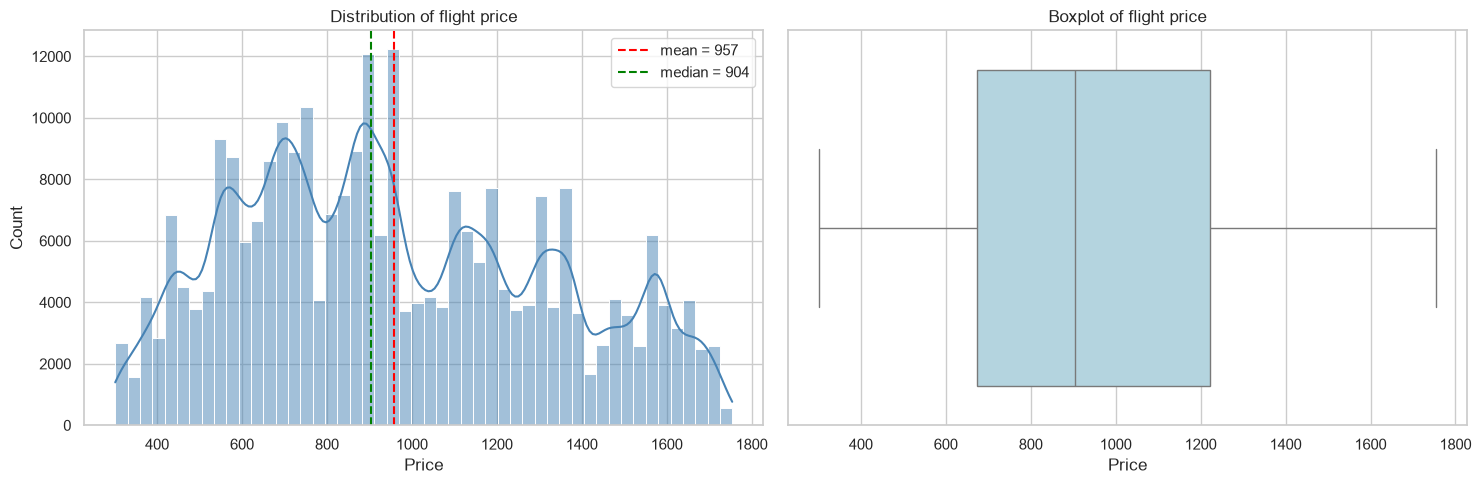

count    271888.00
mean        957.38
std         362.31
min         301.51
25%         672.66
50%         904.00
75%        1222.24
max        1754.17
Name: price, dtype: float64
Skewness: 0.314


In [19]:
# Chart - 1 visualization code
# distribution of the target variable
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(df["price"], bins=50, kde=True, color="steelblue", ax=axes[0])
axes[0].axvline(df["price"].mean(), color="red", ls="--", label=f"mean = {df['price'].mean():.0f}")
axes[0].axvline(df["price"].median(), color="green", ls="--", label=f"median = {df['price'].median():.0f}")
axes[0].set_title("Distribution of flight price")
axes[0].set_xlabel("Price")
axes[0].legend()
sns.boxplot(x=df["price"], color="lightblue", ax=axes[1])
axes[1].set_title("Boxplot of flight price")
axes[1].set_xlabel("Price")
plt.tight_layout()
plt.show()

print(df["price"].describe().round(2))
print("Skewness:", round(df["price"].skew(), 3))

##### 1. Why did you pick the specific chart?

A histogram with a KDE line is the simplest way to see the shape of a numeric column, and price is the target I want to predict. I put a boxplot next to it because it shows the median, the spread and any outliers at a glance.

##### 2. What is/are the insight(s) found from the chart?

Prices go from 301.51 to 1,754.17, with a mean of 957.38 and a median of 904.00. The distribution is only slightly right skewed (skewness 0.314) and it has a few bumps instead of one smooth peak, which makes sense because the three classes sit at different price levels. The boxplot shows no outliers.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. The target is not heavily skewed and has no outliers, so I can model it directly without a log transform, and the errors stay in real currency, which is easy to explain to the business. The several peaks also tell me that class is going to be a key feature. Nothing here points to negative growth, it just describes the price range the company works in.

#### Chart - 2 - Share of bookings by flight class (Univariate)

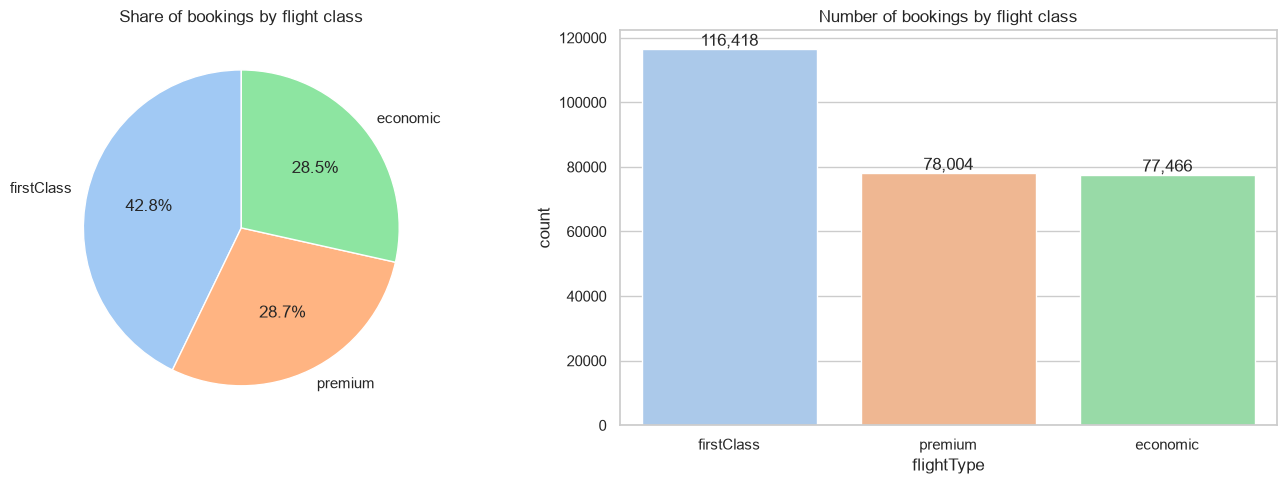

In [20]:
# Chart - 2 visualization code
# share of each flight class
type_counts = df["flightType"].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].pie(type_counts, labels=type_counts.index, autopct="%1.1f%%", startangle=90,
            colors=sns.color_palette("pastel"), wedgeprops={"edgecolor": "white"})
axes[0].set_title("Share of bookings by flight class")
sns.countplot(data=df, x="flightType", order=type_counts.index, palette="pastel", ax=axes[1])
axes[1].set_title("Number of bookings by flight class")
for p in axes[1].patches:
    axes[1].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom")
plt.tight_layout()
plt.show()

##### 1. Why did you pick the specific chart?

Flight class is a categorical column with only three values, so a pie chart shows the part to whole split clearly. The count plot next to it gives the exact numbers.

##### 2. What is/are the insight(s) found from the chart?

First class is the most booked class with 116,418 flights (42.8%). Premium (78,004, 28.7%) and economy (77,466, 28.5%) are almost equal. Part of the reason first class is so large is that FlyingDrops only sells first class tickets.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. First class tickets are the most expensive and also the biggest group, so they bring in most of the revenue. The company should keep first class availability high and make sure its price estimates for first class are right. The risk is that the business depends a lot on first class: if corporate travel budgets get cut, many of these customers could move to cheaper classes and revenue would fall.

#### Chart - 3 - Bookings per agency (Univariate)

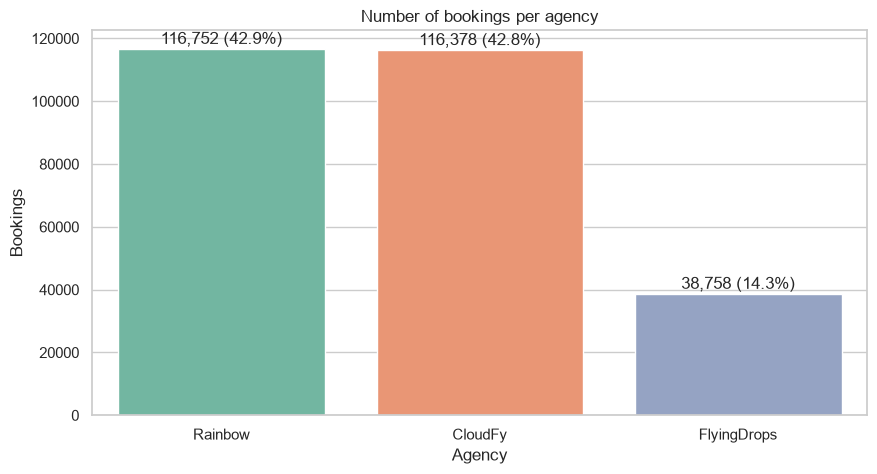

In [21]:
# Chart - 3 visualization code
# bookings per agency
agency_counts = df["agency"].value_counts()
ax = sns.barplot(x=agency_counts.index, y=agency_counts.values, palette="Set2")
for i, v in enumerate(agency_counts.values):
    ax.text(i, v + 1500, f"{v:,} ({v / len(df) * 100:.1f}%)", ha="center")
ax.set_title("Number of bookings per agency")
ax.set_xlabel("Agency")
ax.set_ylabel("Bookings")
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart is the easiest way to compare counts across a few categories. I added the count and the percentage on top of each bar.

##### 2. What is/are the insight(s) found from the chart?

Rainbow (116,752, 42.9%) and CloudFy (116,378, 42.8%) have almost the same number of bookings, while FlyingDrops has only 38,758 (14.3%). FlyingDrops is smaller because it sells first class only.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. The two big agencies handle around 86% of the bookings, so any deal or pricing change with them affects most customers. FlyingDrops could grow by also offering economy and premium seats. On the negative side, two agencies holding almost all the volume is a dependency risk. If one of them left the platform, close to half of the bookings would be affected.

#### Chart - 4 - Flights by origin city (Univariate)

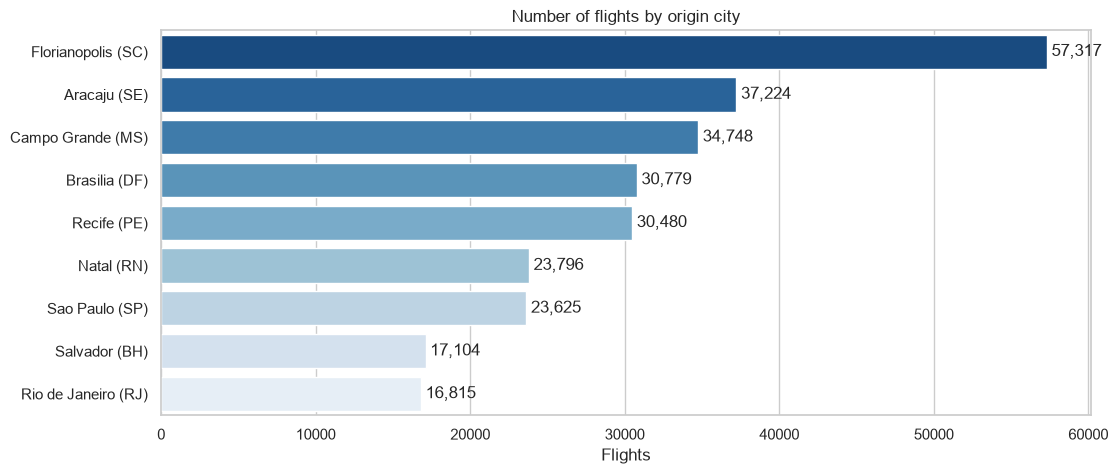

from counts == to counts: True


In [22]:
# Chart - 4 visualization code
# busiest origin cities
origin_counts = df["from"].value_counts()
plt.figure(figsize=(12, 5))
ax = sns.barplot(x=origin_counts.values, y=origin_counts.index, palette="Blues_r")
for i, v in enumerate(origin_counts.values):
    ax.text(v + 300, i, f"{v:,}", va="center")
ax.set_title("Number of flights by origin city")
ax.set_xlabel("Flights")
ax.set_ylabel("")
plt.show()

# the destination counts come out exactly the same because every trip has a return flight
print("from counts == to counts:", (df["from"].value_counts().sort_index() == df["to"].value_counts().sort_index()).all())

##### 1. Why did you pick the specific chart?

A horizontal bar chart sorted by count makes the long city names easy to read and ranks the cities from busiest to quietest.

##### 2. What is/are the insight(s) found from the chart?

Florianopolis (SC) is by far the busiest city with 57,317 departures, much more than the next ones, Aracaju (SE) with 37,224 and Campo Grande (MS) with 34,748. Rio de Janeiro (RJ) with 16,815 and Salvador (BH) with 17,104 are the quietest. The destination counts are exactly the same as the origin counts, because every trip has a return flight.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Florianopolis is the main hub, so it is where marketing and capacity planning should start, for example hotel offers or more agency options there. Rio de Janeiro being last is surprising for such a big city and could be a missed market, partly because the Rio de Janeiro to Salvador route does not exist in the data at all. That gap is a negative point the business could fix by adding the route.

#### Chart - 5 - Distance of flights and routes (Univariate)

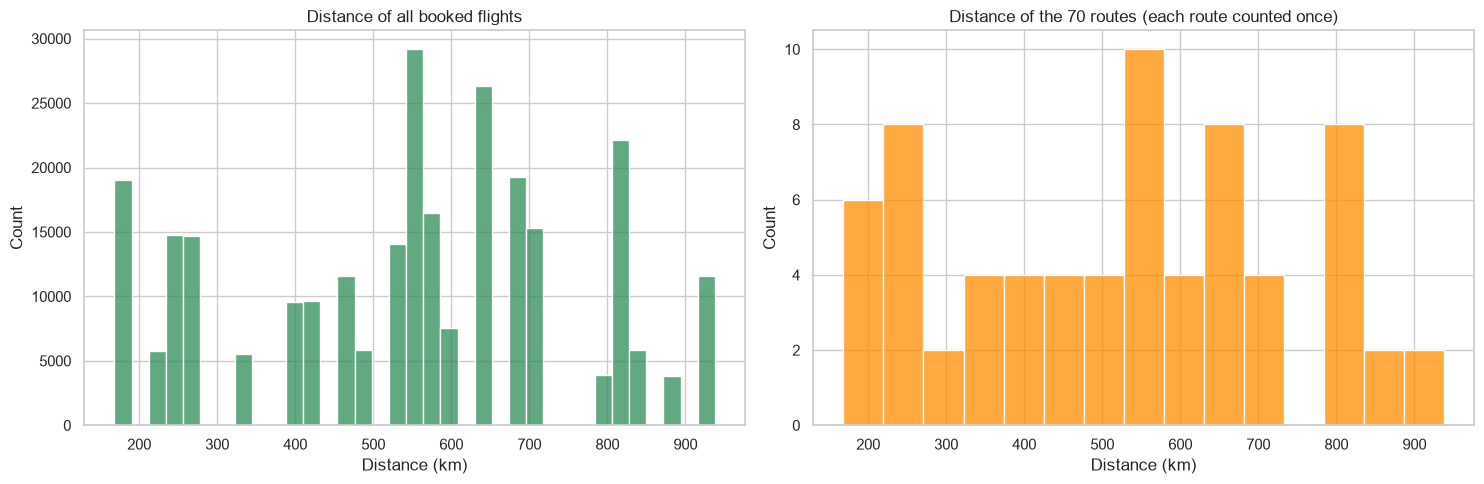

count     70.0
mean     520.7
std      218.6
min      168.2
25%      328.6
50%      550.7
75%      676.6
max      937.8
Name: distance, dtype: float64


In [23]:
# Chart - 5 visualization code
# distance and flight time of the routes
route_info = df.groupby("route")[["distance", "time"]].first()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(df["distance"], bins=35, color="seagreen", ax=axes[0])
axes[0].set_title("Distance of all booked flights")
axes[0].set_xlabel("Distance (km)")
sns.histplot(route_info["distance"], bins=15, color="darkorange", ax=axes[1])
axes[1].set_title("Distance of the 70 routes (each route counted once)")
axes[1].set_xlabel("Distance (km)")
plt.tight_layout()
plt.show()

print(route_info["distance"].describe().round(1))

##### 1. Why did you pick the specific chart?

Histograms show the spread of a numeric column. I drew two versions, one over all bookings and one where each route is counted only once, because busy routes can make the first one misleading.

##### 2. What is/are the insight(s) found from the chart?

The 70 routes go from 168.2 km to 937.8 km, with a mean of 520.7 km. Over all bookings the average distance is higher (about 547 km), so the busiest routes tend to be the longer ones. All flights are domestic and short, under 1,000 km.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Since longer routes are booked more, the company earns more per trip on its busiest routes, and distance will be a strong input for the price model. No negative growth here, but it shows the network is made of short flights, so on the shortest routes (under about 300 km) the company competes with road travel and could lose some demand if it prices them too high.

#### Chart - 6 - Price by flight class (Bivariate: numerical - categorical)

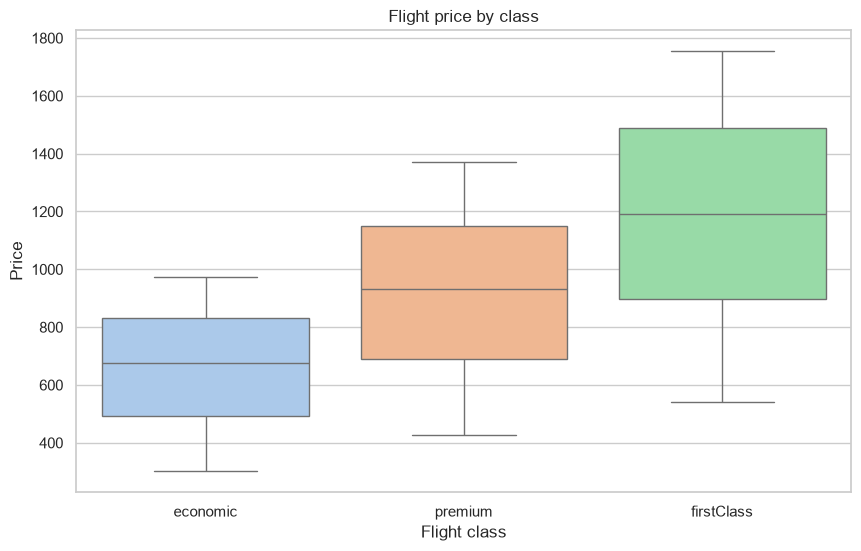

              mean  median    std
flightType                       
economic     658.4   674.5  192.9
premium      920.4   932.8  276.9
firstClass  1181.1  1190.9  346.4


In [24]:
# Chart - 6 visualization code
# price by flight class
order = ["economic", "premium", "firstClass"]
plt.figure(figsize=(10, 6))
sns.boxplot(data=df, x="flightType", y="price", order=order, palette="pastel")
plt.title("Flight price by class")
plt.xlabel("Flight class")
plt.ylabel("Price")
plt.show()

print(df.groupby("flightType")["price"].agg(["mean", "median", "std"]).loc[order].round(1))

##### 1. Why did you pick the specific chart?

A boxplot is good for comparing a numeric variable across categories, because it shows the median, the spread and the outliers of each group side by side.

##### 2. What is/are the insight(s) found from the chart?

There is a clear step between the classes. The mean price is 658.4 for economy, 920.4 for premium and 1,181.1 for first class. The boxes still overlap a bit, because a long economy flight can cost more than a short first class flight. So class alone is not enough to predict the price, the route matters too.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. The gap between classes is large and consistent, which the company can use for upselling. For example, premium costs about 40% more than economy on average (920.4 vs 658.4), so showing both prices side by side could move some customers up a class. There is no negative insight here, though the overlap shows that customers on long routes may pick a lower class because of the cost.

#### Chart - 7 - Price by agency and class (Bivariate / Multivariate)

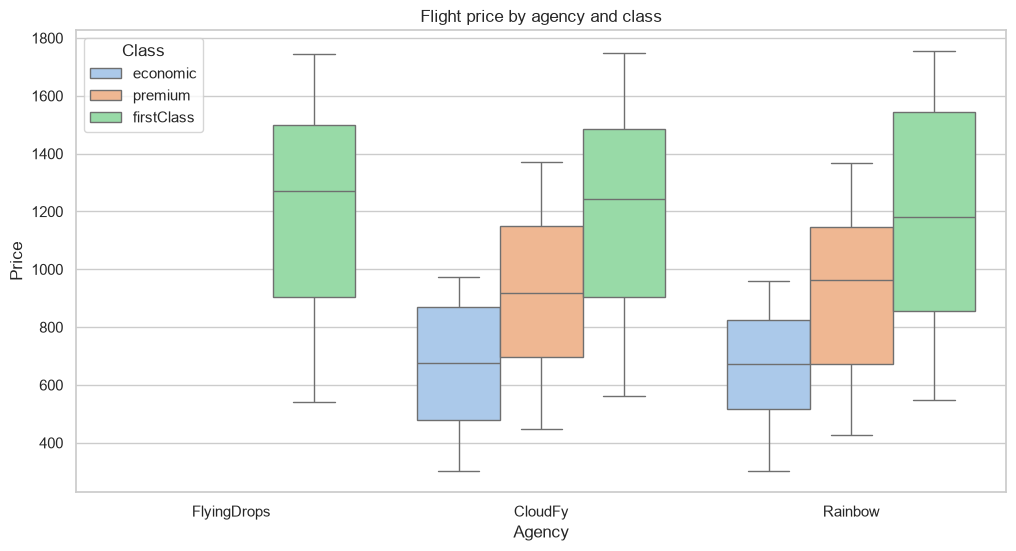

flightType   economic  premium  firstClass
agency                                    
CloudFy         658.9    916.1      1180.3
FlyingDrops       NaN      NaN      1186.2
Rainbow         658.0    924.6      1176.8


In [25]:
# Chart - 7 visualization code
# price by agency, split by class so we compare like with like
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x="agency", y="price", hue="flightType", hue_order=order, palette="pastel")
plt.title("Flight price by agency and class")
plt.xlabel("Agency")
plt.ylabel("Price")
plt.legend(title="Class")
plt.show()

print(df.pivot_table(index="agency", columns="flightType", values="price", aggfunc="mean")[order].round(1))

##### 1. Why did you pick the specific chart?

I wanted to compare the agencies, but comparing them over all classes would be unfair because FlyingDrops only sells first class. A grouped boxplot with class as the colour lets me compare the agencies inside the same class.

##### 2. What is/are the insight(s) found from the chart?

Inside the same class the agencies are almost identical. Economy is 658.9 at CloudFy and 658.0 at Rainbow, premium is 916.1 and 924.6, and first class is 1,180.3 at CloudFy, 1,186.2 at FlyingDrops and 1,176.8 at Rainbow. FlyingDrops only looks expensive in the overall numbers because all of its tickets are first class.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It shows customers are not overpaying with any one agency, so the choice of agency is more about availability than price. It also tells me the model should not treat FlyingDrops as an expensive brand. No negative growth insight, but since prices are the same, agencies will have to compete on service instead.

#### Chart - 8 - Distance vs price by class (Bivariate: numerical - numerical)

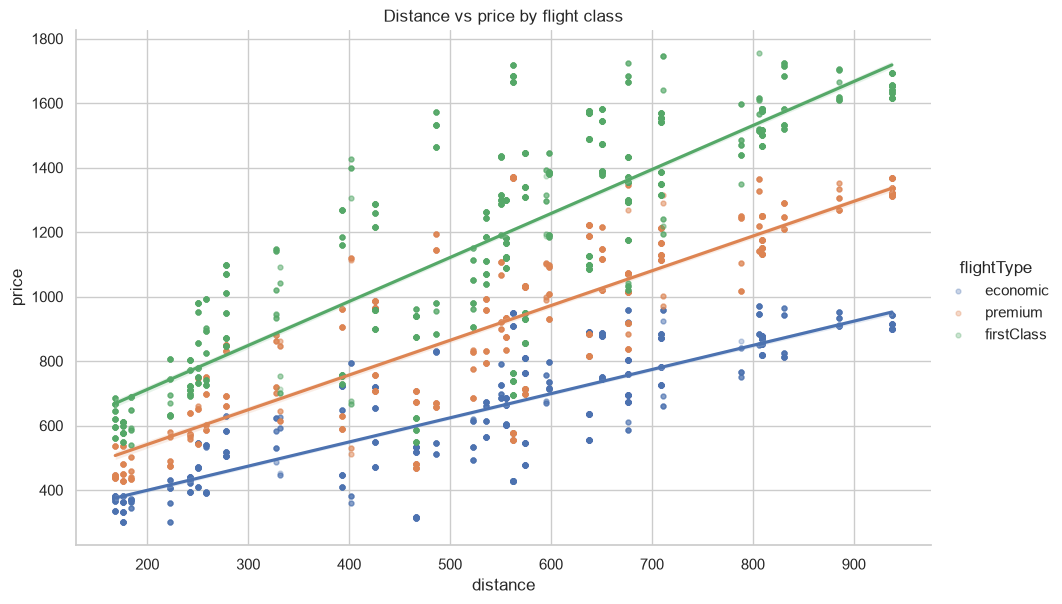

economic    price ~ 249 + 0.75 * distance   (r = 0.816)
premium     price ~ 321 + 1.09 * distance   (r = 0.825)
firstClass  price ~ 433 + 1.37 * distance   (r = 0.822)


In [26]:
# Chart - 8 visualization code
# distance vs price, coloured by class (sample of rows so the plot stays readable)
sample = df.sample(6000, random_state=RANDOM_STATE)
g = sns.lmplot(data=sample, x="distance", y="price", hue="flightType", hue_order=order,
               scatter_kws={"alpha": 0.3, "s": 12}, height=6, aspect=1.6, palette="deep")
g.ax.set_title("Distance vs price by flight class")
plt.show()

for t in order:
    part = df[df["flightType"] == t]
    slope, intercept = np.polyfit(part["distance"], part["price"], 1)
    r = part[["distance", "price"]].corr().iloc[0, 1]
    print(f"{t:<11} price ~ {intercept:.0f} + {slope:.2f} * distance   (r = {r:.3f})")

##### 1. Why did you pick the specific chart?

A scatter plot is the standard way to look at the relationship between two numeric variables. I coloured the points by class and added a regression line for each class to see whether the slope changes.

##### 2. What is/are the insight(s) found from the chart?

Price goes up with distance in every class and the relationship is fairly strong (r between 0.816 and 0.825). The slope depends on the class: about 0.75 per km for economy, 1.09 for premium and 1.37 for first class, on top of a base price of roughly 249, 321 and 433. The points form vertical stripes because each route has one fixed distance. The spread inside a stripe comes from the route itself and the agency.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It gives a simple pricing rule that is easy to explain to customers, a base fee plus a rate per km that depends on the class. It also tells me a linear model will capture most of the price but not all of it, since the spread around each line is the route specific part. Nothing here points to negative growth.

#### Chart - 9 - Bookings by agency and class (Bivariate: categorical - categorical)

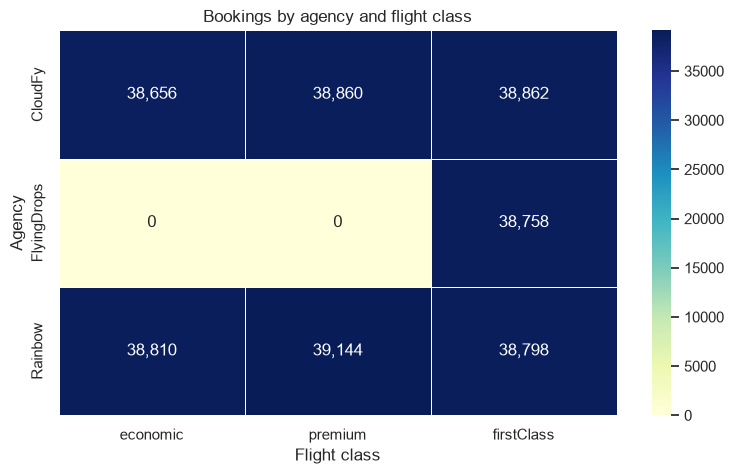

In [27]:
# Chart - 9 visualization code
# agency vs class (categorical - categorical)
ct = pd.crosstab(df["agency"], df["flightType"])[order]
plt.figure(figsize=(9, 5))
sns.heatmap(ct, annot=True, fmt=",d", cmap="YlGnBu", linewidths=0.5)
plt.title("Bookings by agency and flight class")
plt.xlabel("Flight class")
plt.ylabel("Agency")
plt.show()

##### 1. Why did you pick the specific chart?

Both columns are categorical, so a heatmap of the cross tab shows how often each combination happens and also makes the empty combinations obvious.

##### 2. What is/are the insight(s) found from the chart?

CloudFy and Rainbow split their bookings almost equally across the three classes, between about 38,600 and 39,100 each. FlyingDrops has 38,758 first class bookings and none in economy or premium.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. FlyingDrops is missing about two thirds of the market by selling only first class. Adding economy and premium seats could help it grow and would give customers more choice. For the model it means some combinations, like FlyingDrops economy, never appear in the data, so a prediction for them would only be a guess and should be treated with care.

#### Chart - 10 - Average economy price by route (Multivariate)

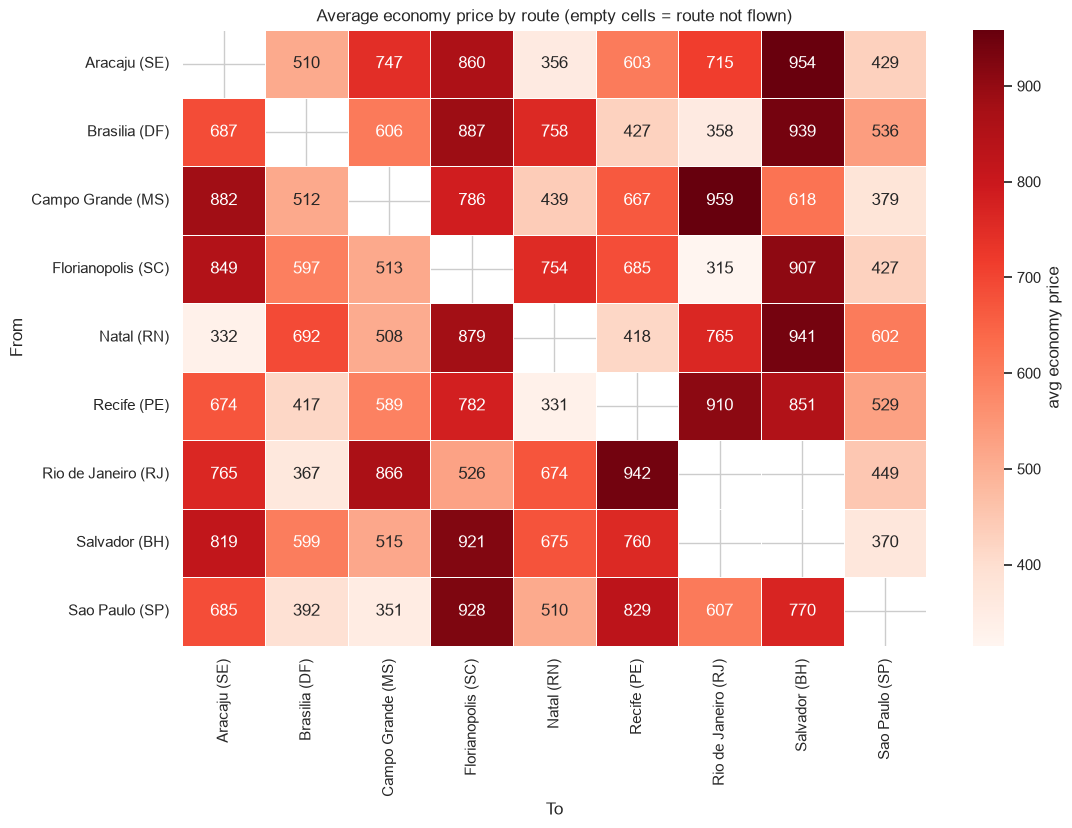

Average price difference between A->B and B->A: 23.5%


In [28]:
# Chart - 10 visualization code
# average economy price for every origin / destination pair
eco = df[df["flightType"] == "economic"]
route_price = eco.pivot_table(index="from", columns="to", values="price", aggfunc="mean")
plt.figure(figsize=(12, 8))
sns.heatmap(route_price, annot=True, fmt=".0f", cmap="Reds", linewidths=0.5, cbar_kws={"label": "avg economy price"})
plt.title("Average economy price by route (empty cells = route not flown)")
plt.xlabel("To")
plt.ylabel("From")
plt.show()

# same route in both directions does not cost the same
both = route_price.stack().rename("price").reset_index()
both["reverse"] = both.apply(lambda r: route_price.loc[r["to"], r["from"]], axis=1)
both["diff_pct"] = (both["price"] - both["reverse"]).abs() / both["reverse"] * 100
print(f"Average price difference between A->B and B->A: {both['diff_pct'].mean():.1f}%")

##### 1. Why did you pick the specific chart?

I wanted to see the price of every origin and destination pair at once. A heatmap with the origin on one axis and the destination on the other is the most compact way to show all 70 routes. I used economy only so that the class does not mix into the colours.

##### 2. What is/are the insight(s) found from the chart?

Economy prices go from about 315 (Florianopolis to Rio de Janeiro) up to about 959 (Campo Grande to Rio de Janeiro). Flights into Florianopolis and Salvador are among the most expensive. The same pair of cities does not cost the same in both directions: on average A to B and B to A differ by 23.5%. For example, Florianopolis to Rio de Janeiro is 315 but Rio de Janeiro to Florianopolis is 526. The two empty cells are the Rio de Janeiro and Salvador routes, which are never flown.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Knowing which routes and directions are expensive helps the company plan promotions, for example discounts on the expensive direction to fill seats. It also shows why the route has to be part of the model, since distance alone cannot explain why one direction costs much more than the other. On the negative side, very expensive routes like Campo Grande to Rio de Janeiro may put customers off, and the missing Rio de Janeiro to Salvador route is lost business.

#### Chart - 11 - Flights and average price over time (Bivariate: time - numerical)

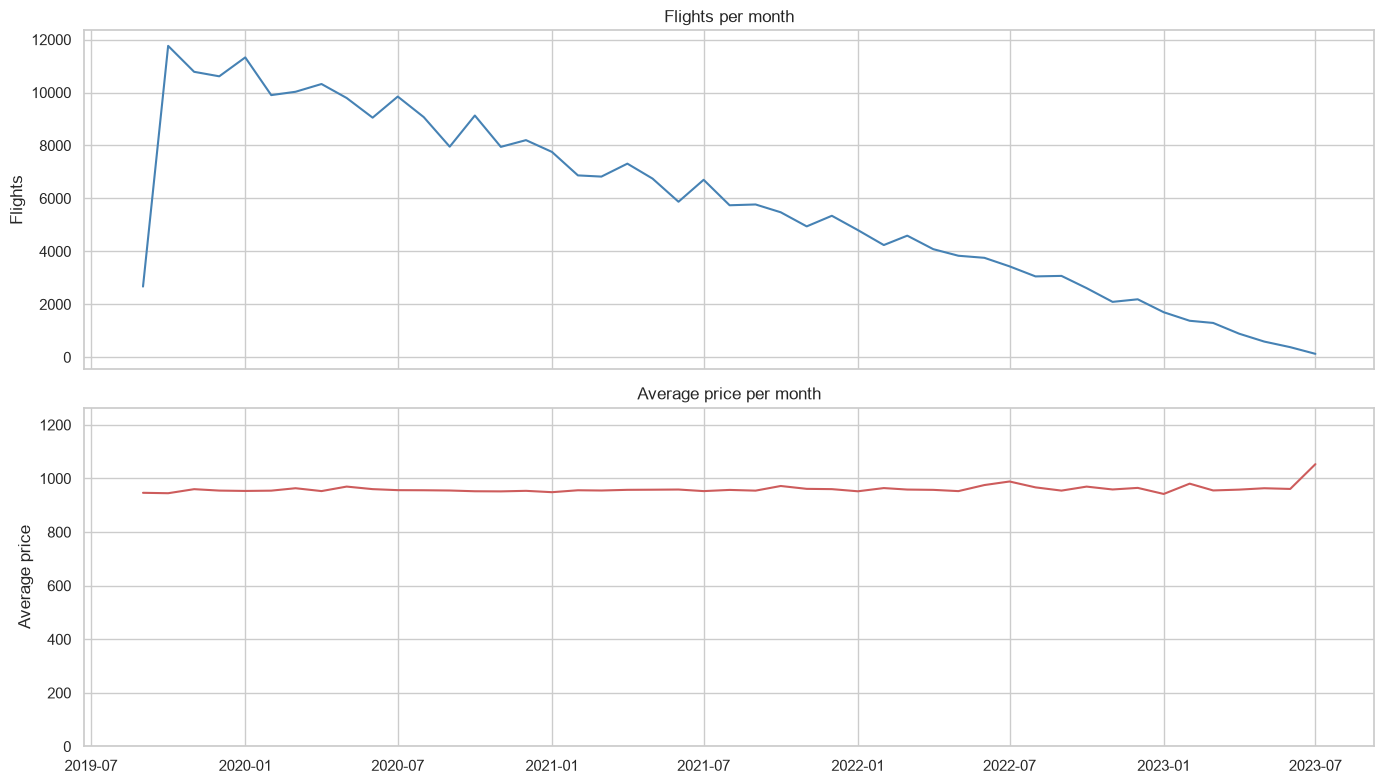

      flights  avg_price
year                    
2019    35826      952.5
2020   112571      956.7
2021    75363      957.2
2022    41761      963.1
2023     6367      960.8


In [29]:
# Chart - 11 visualization code
# bookings and average price over time
monthly = df.set_index("date").resample("MS").agg({"price": ["size", "mean"]})
monthly.columns = ["flights", "avg_price"]
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
axes[0].plot(monthly.index, monthly["flights"], color="steelblue")
axes[0].set_title("Flights per month")
axes[0].set_ylabel("Flights")
axes[1].plot(monthly.index, monthly["avg_price"], color="indianred")
axes[1].set_title("Average price per month")
axes[1].set_ylabel("Average price")
axes[1].set_ylim(0, monthly["avg_price"].max() * 1.2)
plt.tight_layout()
plt.show()

print(df.groupby("year").agg(flights=("price", "size"), avg_price=("price", "mean")).round(1))

##### 1. Why did you pick the specific chart?

Line charts are the natural choice for data over time. I put the monthly number of flights and the monthly average price in two panels with the same time axis so I could compare the two trends.

##### 2. What is/are the insight(s) found from the chart?

Bookings were highest right at the start, close to 12,000 flights a month in late 2019, and then dropped steadily, down to a few hundred a month by mid 2023. By year there were 112,571 flights in 2020, 75,363 in 2021, 41,761 in 2022 and 6,367 in the part of 2023 that is covered. The average price stayed flat between 952.5 and 963.1 per year, so the drop in volume did not come with any price change. The small jump at the very end comes from the last month having very few flights.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

This is the most worrying chart. The number of bookings has been falling for almost four years, which is clear negative growth. Prices did not change, so pricing is not the reason. It could be users booking less often or booking somewhere else, and the business should look at user retention. For the model, it means new data keeps coming in smaller amounts and the model has to be retrained regularly to stay up to date. The positive side is that stable prices make the price model reliable over time.

#### Chart - 12 - Average price and first class share by company (Bivariate)

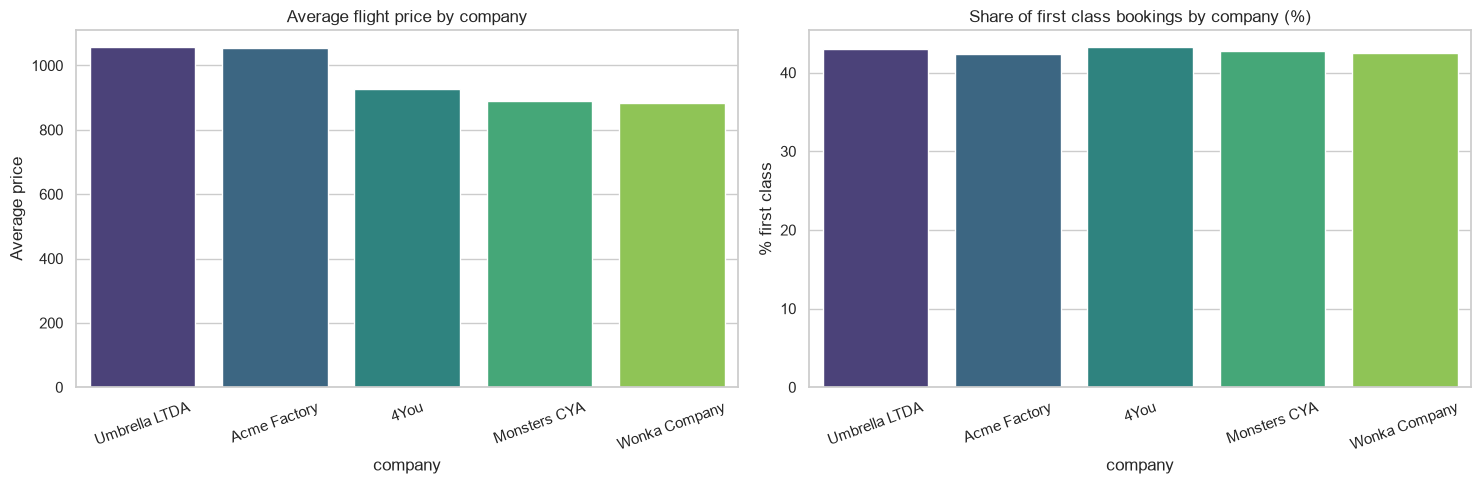

               avg_price  flights  first_class_share  avg_distance
company                                                           
Umbrella LTDA     1056.0    41596               43.0         671.7
Acme Factory      1052.9    50944               42.3         671.6
4You               927.5    92986               43.2         503.1
Monsters CYA       889.0    40480               42.8         469.2
Wonka Company      882.8    45882               42.4         453.0


In [30]:
# Chart - 12 visualization code
# average price and bookings by the company the user works for
comp = df.groupby("company").agg(avg_price=("price", "mean"), flights=("price", "size"),
                                 first_class_share=("flightType", lambda s: (s == "firstClass").mean() * 100),
                                 avg_distance=("distance", "mean"))
comp = comp.sort_values("avg_price", ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(x=comp.index, y=comp["avg_price"], palette="viridis", ax=axes[0])
axes[0].set_title("Average flight price by company")
axes[0].set_ylabel("Average price")
axes[0].tick_params(axis="x", rotation=20)
sns.barplot(x=comp.index, y=comp["first_class_share"], palette="viridis", ax=axes[1])
axes[1].set_title("Share of first class bookings by company (%)")
axes[1].set_ylabel("% first class")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

print(comp.round(1))

##### 1. Why did you pick the specific chart?

Bar charts make it easy to compare one number across a handful of groups. I put the average price next to the share of first class bookings to check whether a price difference comes from the class mix.

##### 2. What is/are the insight(s) found from the chart?

Umbrella LTDA (1,056.0) and Acme Factory (1,052.9) pay clearly more per flight than 4You (927.5), Monsters CYA (889.0) and Wonka Company (882.8). The share of first class is almost the same for all five companies (42.3% to 43.2%), so class is not the reason. The reason is distance: Umbrella and Acme employees fly about 672 km on average, against 453 to 503 km for the other three.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. It shows which corporate clients bring the most revenue per trip, and that it comes from the routes they fly rather than the class they choose. The company could offer route based corporate deals to Umbrella LTDA and Acme Factory. For the model it confirms that the user's company does not need to be a feature, because its effect is already explained by the route.

#### Chart - 13 - Average price by age group and gender (Multivariate)

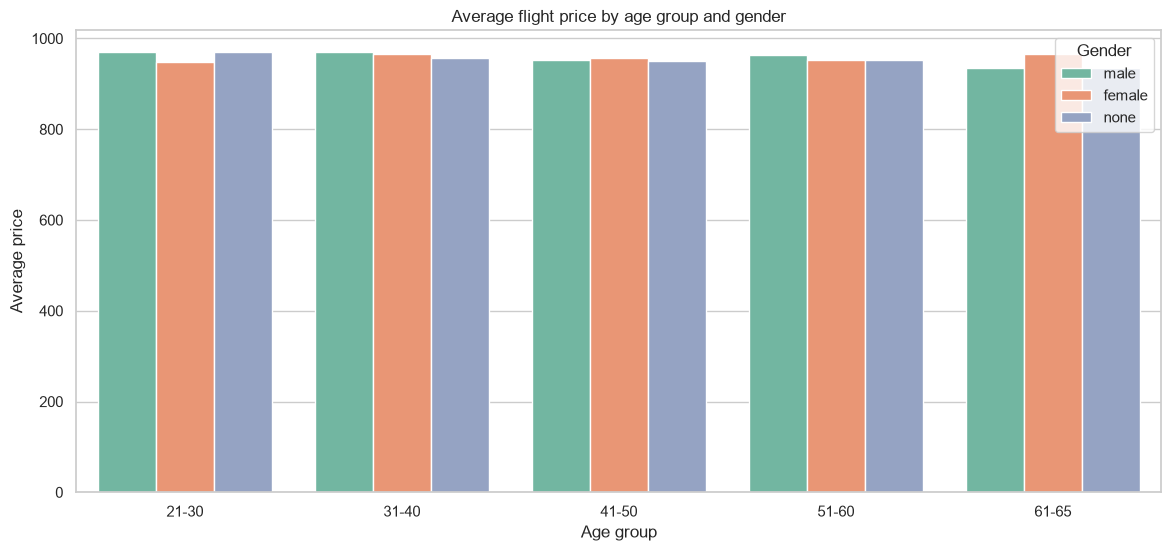

flightType  economic  premium  firstClass
age_group                                
21-30          661.6    924.6      1186.2
31-40          664.2    927.7      1189.0
41-50          653.7    911.6      1177.1
51-60          658.9    920.6      1179.5
61-65          648.6    913.8      1165.5


In [31]:
# Chart - 13 visualization code
# multivariate: average price by age group, gender and class
plt.figure(figsize=(14, 6))
sns.barplot(data=df, x="age_group", y="price", hue="gender", errorbar=None, palette="Set2")
plt.title("Average flight price by age group and gender")
plt.xlabel("Age group")
plt.ylabel("Average price")
plt.legend(title="Gender")
plt.show()

print(df.pivot_table(index="age_group", columns="flightType", values="price", aggfunc="mean", observed=True)[order].round(1))

##### 1. Why did you pick the specific chart?

I wanted to see whether age and gender change what people pay. A grouped bar chart puts three variables in one picture: age group on the x axis, gender as the colour and the average price as the bar height.

##### 2. What is/are the insight(s) found from the chart?

The bars are almost flat. The average price is close to the overall average of about 957 for every age group and gender. Within each class the numbers barely move with age either: economy is between 648.6 and 664.2 and first class between 1,165.5 and 1,189.0 across the age groups. The 61-65 group pays slightly less, but the difference is small.

##### 3. Will the gained insights help creating a positive business impact? 
Are there any insights that lead to negative growth? Justify with specific reason.

It helps in a different way: personal details like age and gender do not drive the price, so the model does not need them, which is also better for fairness and privacy. There is no negative growth insight here, but it suggests that marketing aimed at a certain age group would not change ticket revenue much.

#### Chart - 14 - Correlation Heatmap

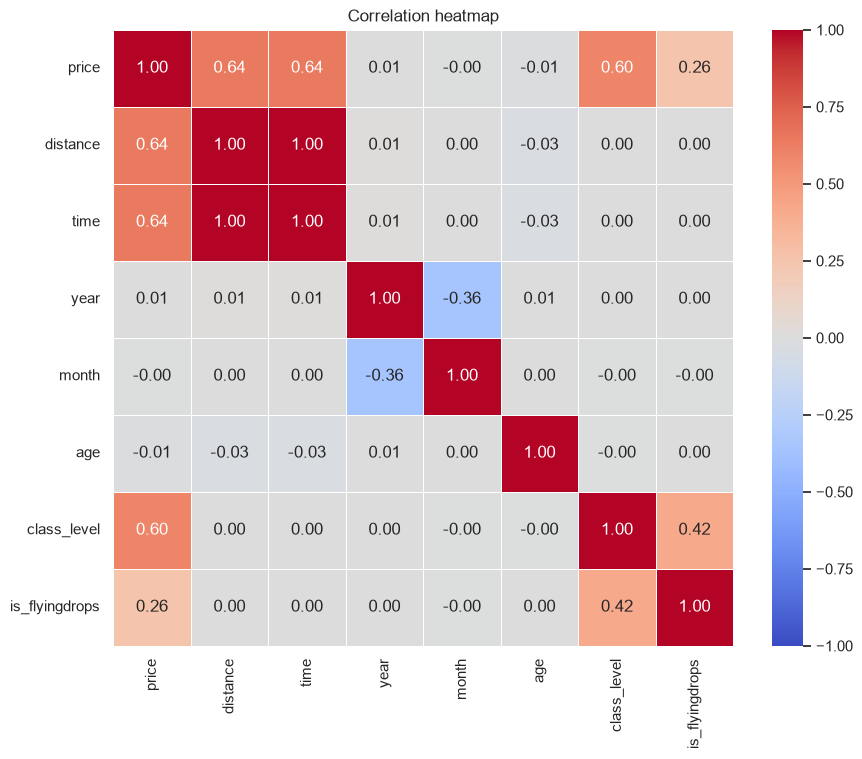

In [32]:
# Correlation Heatmap visualization code
corr_df = df[["price", "distance", "time", "year", "month", "age"]].copy()
corr_df["class_level"] = df["flightType"].map({"economic": 0, "premium": 1, "firstClass": 2})
corr_df["is_flyingdrops"] = (df["agency"] == "FlyingDrops").astype(int)
plt.figure(figsize=(10, 8))
sns.heatmap(corr_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation heatmap")
plt.show()

##### 1. Why did you pick the specific chart?

A correlation heatmap shows all the pairwise linear relationships in one view. Price, distance and time are the main numeric columns, and I also added two encoded columns, the class level (0 = economy, 1 = premium, 2 = first class) and a FlyingDrops flag, so the main categorical drivers show up as well.

##### 2. What is/are the insight(s) found from the chart?

Price is correlated with distance (0.64), time (0.64) and class level (0.60). Distance and time have a correlation of 1.00, so they carry the same information (the planes fly at about 385 km/h on every route). The FlyingDrops flag has 0.26 with price, but that is only because it is linked to the class level (0.42). Year, month and age are all close to 0 with price, which matches the earlier charts. Class level and distance are not correlated with each other (0.00), so they add separate information to the model.

#### Chart - 15 - Pair Plot 

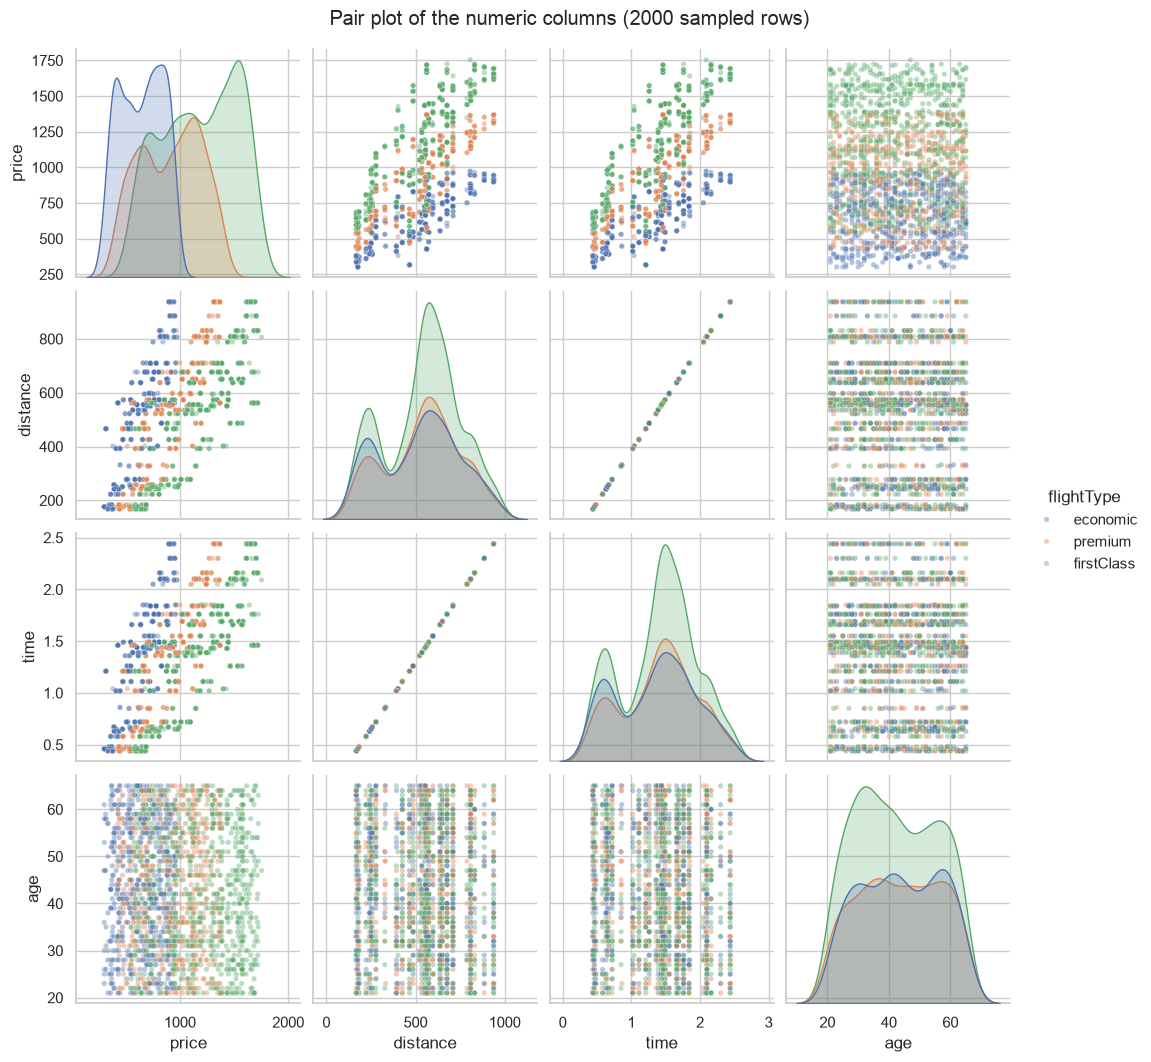

In [33]:
# Pair Plot visualization code
pair_sample = df.sample(2000, random_state=RANDOM_STATE)[["price", "distance", "time", "age", "flightType"]]
sns.pairplot(pair_sample, hue="flightType", hue_order=order, plot_kws={"alpha": 0.4, "s": 15}, height=2.6)
plt.suptitle("Pair plot of the numeric columns (2000 sampled rows)", y=1.02)
plt.show()

##### 1. Why did you pick the specific chart?

A pair plot shows the distribution of each numeric column and the scatter plot of every pair, so it is a good final check before modelling. I used a sample of 2,000 rows to keep it readable and coloured the points by class.

##### 2. What is/are the insight(s) found from the chart?

The price vs distance and price vs time panels look the same and both show three bands, one per class. Distance vs time is a perfect straight line, which confirms they are copies of each other. Age shows no pattern with price, distance or time. On the diagonal, the price distribution of first class sits clearly to the right of premium and economy, which again shows class as the main driver of price.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

Based on the charts I picked these three statements:

1. First class tickets are more expensive on average than economy tickets (Chart 6).
2. FlyingDrops charges more than the other agencies. It looks like this in the overall averages, but Chart 7 suggests it is not true inside the same class.
3. The date of the flight affects its price. Chart 11 suggests it does not.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **Null hypothesis (H0):** the mean price of first class tickets is equal to or lower than the mean price of economy tickets.
* **Alternate hypothesis (H1):** the mean price of first class tickets is higher than the mean price of economy tickets.

#### 2. Perform an appropriate statistical test.

In [34]:
# Perform Statistical Test to obtain P-Value
first = df.loc[df["flightType"] == "firstClass", "price"]
economy = df.loc[df["flightType"] == "economic", "price"]

# one sided Welch t-test: is the first class mean greater than the economy mean?
t_stat, p_value = stats.ttest_ind(first, economy, equal_var=False, alternative="greater")
print(f"First class mean: {first.mean():.2f}  |  Economy mean: {economy.mean():.2f}")
print(f"t statistic = {t_stat:.2f}, p-value = {p_value:.3e}")
print("Reject H0" if p_value < 0.05 else "Fail to reject H0")

First class mean: 1181.07  |  Economy mean: 658.44
t statistic = 425.14, p-value = 0.000e+00
Reject H0


##### Which statistical test have you done to obtain P-Value?

I used a one sided Welch two sample t-test (`scipy.stats.ttest_ind` with `equal_var=False` and `alternative="greater"`). The t statistic is 425.14 and the p-value is 0.000 (too small to print), so I reject H0. First class has a mean of 1,181.07 against 658.44 for economy.

##### Why did you choose the specific statistical test?

I am comparing the means of two independent groups. The two groups have very different spreads (standard deviation 346.4 vs 192.9), so the normal t-test that assumes equal variances is not a good fit, and Welch's version does not need that assumption. With more than 77,000 rows in each group the t-test is valid even though the prices are not perfectly normal. I made it one sided because the question is whether first class is higher, not just different.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **Null hypothesis (H0):** on the same route, first class tickets cost the same with CloudFy, FlyingDrops and Rainbow.
* **Alternate hypothesis (H1):** on the same route, at least one agency charges a different price for first class.

#### 2. Perform an appropriate statistical test.

In [35]:
# Perform Statistical Test to obtain P-Value
fc = df[df["flightType"] == "firstClass"]

# the naive comparison first: FlyingDrops vs the other two agencies over all classes
fd_all = df.loc[df["agency"] == "FlyingDrops", "price"]
others_all = df.loc[df["agency"] != "FlyingDrops", "price"]
print(f"Naive: FlyingDrops mean {fd_all.mean():.1f} vs others {others_all.mean():.1f}")

# fair comparison: first class only, same route, three agencies -> Friedman test (routes are the blocks)
route_agency = fc.pivot_table(index="route", columns="agency", values="price", aggfunc="first")
stat, p_value = stats.friedmanchisquare(route_agency["CloudFy"], route_agency["FlyingDrops"], route_agency["Rainbow"])
print("\nFirst class mean price per agency (same 70 routes):")
print(route_agency.mean().round(1))
print(f"\nFriedman chi-square = {stat:.3f}, p-value = {p_value:.4f}")
print("Reject H0" if p_value < 0.05 else "Fail to reject H0")

Naive: FlyingDrops mean 1186.2 vs others 919.3

First class mean price per agency (same 70 routes):
agency
CloudFy        1153.0
FlyingDrops    1157.7
Rainbow        1154.8
dtype: float64

Friedman chi-square = 0.114, p-value = 0.9445
Fail to reject H0


##### Which statistical test have you done to obtain P-Value?

I used the Friedman test (`scipy.stats.friedmanchisquare`) on a table with the 70 routes as rows and the three agencies as columns, using first class prices only. The result was chi-square = 0.114 with a p-value of 0.9445, so I fail to reject H0.

The naive comparison said FlyingDrops costs 1,186.2 on average against 919.3 for the other two agencies. But on the same routes and in the same class the three agencies average 1,153.0 (CloudFy), 1,157.7 (FlyingDrops) and 1,154.8 (Rainbow), which is practically the same. The gap in the naive numbers only comes from FlyingDrops selling first class and nothing else.

##### Why did you choose the specific statistical test?

The three agencies are compared on the same routes, so the samples are related (matched by route) and not independent. Friedman is the non parametric test for three or more related groups, a bit like a repeated measures ANOVA that does not need normal data. Using the route as the block removes the effect of the route, which is the main thing that changes the price, and leaves only the agency effect to test.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **Null hypothesis (H0):** there is no monotonic relationship between the flight date and the price (Spearman correlation = 0).
* **Alternate hypothesis (H1):** the price changes with the flight date (Spearman correlation is not 0).

#### 2. Perform an appropriate statistical test.

In [36]:
# Perform Statistical Test to obtain P-Value
# Spearman rank correlation between the flight date and the price
date_num = df["date"].map(pd.Timestamp.toordinal)
rho, p_value = stats.spearmanr(date_num, df["price"])
print(f"Spearman rho = {rho:.4f}, p-value = {p_value:.3e}, rho^2 = {rho ** 2:.6f}")
print("Reject H0" if p_value < 0.05 else "Fail to reject H0")

# a direct check: inside one route + class + agency, does the price ever move with the date?
spread = df.groupby(["from", "to", "flightType", "agency"])["price"].std()
print(f"\nLargest price standard deviation inside a route/class/agency group: {spread.max():.4f}")

Spearman rho = 0.0075, p-value = 8.503e-05, rho^2 = 0.000057
Reject H0

Largest price standard deviation inside a route/class/agency group: 0.0000


##### Which statistical test have you done to obtain P-Value?

I used the Spearman rank correlation test (`scipy.stats.spearmanr`) between the date (converted to a number) and the price. The result was rho = 0.0075 with a p-value of 8.5e-05, so strictly speaking H0 is rejected. But rho squared is 0.000057, so the date explains less than 0.01% of the variation in price.

On top of that, inside every route/class/agency group the largest standard deviation of the price is 0.0000, so the price of the same flight never changes with the date. The tiny correlation only comes from the mix of routes shifting a little over time. My conclusion is that the date has no practical effect on price, and I do not use it as a feature.

##### Why did you choose the specific statistical test?

A date is ordered, and any relationship with price does not have to be a straight line, so a rank correlation like Spearman fits better than Pearson. It also does not assume normal data. I added the effect size (rho squared) and the within group check because with 271,888 rows even a tiny correlation becomes "significant", and the p-value on its own would be misleading.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [37]:
# Handling Missing Values & Missing Value Imputation
print("Missing values per column:")
print(df[["from", "to", "flightType", "agency", "distance", "time", "price"]].isnull().sum())

# there is nothing to impute, but if a future data load has gaps this is what I would do:
# numbers -> median, categories -> most frequent value
def impute(frame):
    frame = frame.copy()
    for col in frame.columns:
        if frame[col].isnull().any():
            if pd.api.types.is_numeric_dtype(frame[col]):
                frame[col] = frame[col].fillna(frame[col].median())
            else:
                frame[col] = frame[col].fillna(frame[col].mode()[0])
    return frame

df = impute(df)
print("\nMissing values left:", df.isnull().sum().sum())

Missing values per column:
from          0
to            0
flightType    0
agency        0
distance      0
time          0
price         0
dtype: int64

Missing values left: 0


#### What all missing value imputation techniques have you used and why did you use those techniques?

The data has no missing values in any column, so no imputation was actually needed. I still wrote a small `impute` function (median for numeric columns, most frequent value for text columns) so the notebook does not break if a future data load has a few gaps. The median is safer than the mean because it is not pulled by extreme values, and the most frequent value is the usual choice for categories. In the deployed API missing fields are handled differently: the request is rejected with a clear error message instead of guessing a value.

### 2. Handling Outliers

In [38]:
# Handling Outliers & Outlier treatments
def iqr_outliers(series):
    q1, q3 = series.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((series < q1 - 1.5 * iqr) | (series > q3 + 1.5 * iqr)).sum()

for col in ["price", "distance", "time"]:
    print(f"{col:<9} IQR outliers: {iqr_outliers(df[col])}")

# the same check inside each class, since first class prices are naturally higher
print("\nPrice outliers within each class:")
print(df.groupby("flightType")["price"].apply(iqr_outliers))

price     IQR outliers: 0
distance  IQR outliers: 0
time      IQR outliers: 0

Price outliers within each class:
flightType
economic      0
firstClass    0
premium       0
Name: price, dtype: int64


##### What all outlier treatment techniques have you used and why did you use those techniques?

I used the IQR rule (values below Q1 - 1.5 x IQR or above Q3 + 1.5 x IQR) on price, distance and time, first on the whole data and then inside each class. Every check found 0 outliers, so I did not remove or cap anything. This makes sense because all prices come from a fixed price list. If outliers ever did show up, I would first check whether they are data errors before capping them, because a very expensive route can still be a real price.

### 3. Categorical Encoding

In [39]:
# Encode your categorical columns
CATEGORICAL = ["from", "to", "flightType", "agency"]
NUMERIC = ["distance", "time"]

encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
encoded = encoder.fit_transform(df[CATEGORICAL])
print("Columns after one-hot encoding:", encoded.shape[1])
print(encoder.get_feature_names_out()[:12], "...")

# the encoder is put inside a ColumnTransformer + Pipeline below, so the exact same
# encoding is applied at training time and inside the API
def build_preprocessor():
    return ColumnTransformer(
        [("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL)],
        remainder="passthrough",   # distance and time are passed through as they are
    )

Columns after one-hot encoding: 24
['from_Aracaju (SE)' 'from_Brasilia (DF)' 'from_Campo Grande (MS)'
 'from_Florianopolis (SC)' 'from_Natal (RN)' 'from_Recife (PE)'
 'from_Rio de Janeiro (RJ)' 'from_Salvador (BH)' 'from_Sao Paulo (SP)'
 'to_Aracaju (SE)' 'to_Brasilia (DF)' 'to_Campo Grande (MS)'] ...


#### What all categorical encoding techniques have you used & why did you use those techniques?

I used one-hot encoding for the four categorical columns (from, to, flightType and agency), which turns them into 24 binary columns. None of these categories has a natural numeric order (a city or an agency is not "bigger" than another), so label encoding would give the linear model a fake order. Flight class does have an order, but one-hot encoding still works well and lets the model learn a separate effect for each class.

I set `handle_unknown="ignore"` so an unexpected value at prediction time does not crash the pipeline, and the encoder sits inside a ColumnTransformer and Pipeline, so exactly the same encoding is used in training and in the API.

### 4. Textual Data Preprocessing 
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

This dataset has no free text. Every text column is a fixed category with a small number of values (9 cities, 3 classes and 3 agencies), so the NLP steps below do not apply. I kept the cells to follow the template and used a couple of them to check that the categories are clean (no case variants and no extra spaces).

#### 1. Expand Contraction

In [40]:
# Expand Contraction - not applicable: the flights data has no free text column, every text field is a fixed category
print("skipped")

skipped


#### 2. Lower Casing

In [41]:
# Lower Casing - not applicable, but checking that categories have no case variants
for col in ["from", "to", "flightType", "agency"]:
    print(col, df[col].nunique() == df[col].str.lower().nunique())

from True
to True


flightType True
agency True


#### 3. Removing Punctuations

In [42]:
# Remove Punctuations - not applicable, city names like 'Recife (PE)' must stay exactly as they are
print("skipped")

skipped


#### 4. Removing URLs & Removing words and digits contain digits.

In [43]:
# Remove URLs & Remove words and digits contain digits - not applicable, no URLs or free text
print("skipped")

skipped


#### 5. Removing Stopwords & Removing White spaces

In [44]:
# Remove Stopwords - not applicable, no sentences in this dataset
print("skipped")

skipped


In [45]:
# Remove White spaces - only checking for stray spaces in the category values
for col in ["from", "to", "flightType", "agency"]:
    print(col, (df[col] != df[col].str.strip()).sum(), "values with extra spaces")

from 0 values with extra spaces
to 0 values with extra spaces
flightType 0 values with extra spaces
agency 0 values with extra spaces


#### 6. Rephrase Text

In [46]:
# Rephrase Text - not applicable
print("skipped")

skipped


#### 7. Tokenization

In [47]:
# Tokenization - not applicable
print("skipped")

skipped


#### 8. Text Normalization

In [48]:
# Normalizing Text (i.e., Stemming, Lemmatization etc.) - not applicable
print("skipped")

skipped


##### Which text normalization technique have you used and why?

Not applicable. There are no sentences or words to stem or lemmatize. The text columns are category labels and have to stay exactly as they are so they match the values sent to the API.

#### 9. Part of speech tagging

In [49]:
# POS Taging - not applicable
print("skipped")

skipped


#### 10. Text Vectorization

In [50]:
# Vectorizing Text - not applicable, categories are one-hot encoded instead (see Categorical Encoding)
print("skipped")

skipped


##### Which text vectorization technique have you used and why?

Not applicable. Text vectorization like TF-IDF is meant for free text. Here the categorical columns are turned into numbers with one-hot encoding in the Categorical Encoding step instead.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [51]:
# Manipulate Features to minimize feature correlation and create new features
# date parts were created during wrangling (year, month, day_of_week). Here I check how
# strongly distance and time overlap, since they look like the same information
print("Correlation distance vs time:", round(df["distance"].corr(df["time"]), 5))
print("km per hour across routes:")
print((df["distance"] / df["time"]).describe().round(1))

# IDs (travelCode, userCode) are just row identifiers, and price_per_km is built from the target,
# so none of them can be used as model inputs
drop_cols = ["travelCode", "userCode", "price_per_km"]
print("\nColumns that will not be used as features:", drop_cols)

Correlation distance vs time: 0.99999
km per hour across routes:
count    271888.0
mean        384.8
std           0.9
min         382.0
25%         384.3
50%         385.0
75%         385.4
max         386.2
dtype: float64

Columns that will not be used as features: ['travelCode', 'userCode', 'price_per_km']


#### 2. Feature Selection

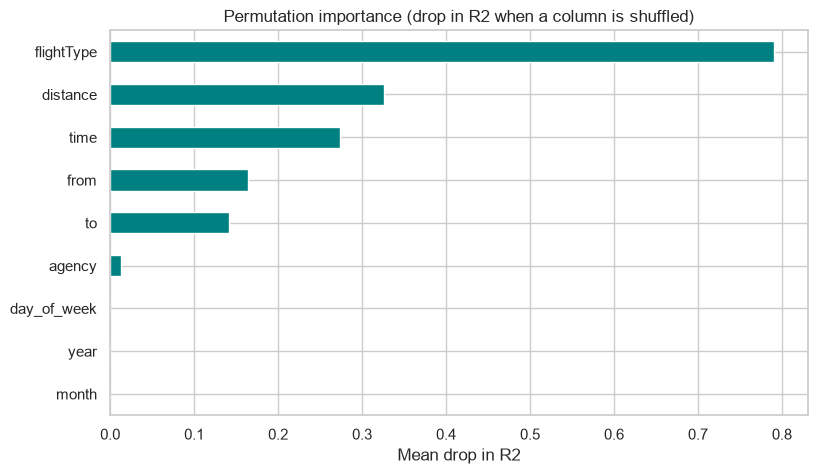

flightType     0.7911
distance       0.3263
time           0.2742
from           0.1642
to             0.1420
agency         0.0126
day_of_week    0.0001
year           0.0000
month         -0.0000
dtype: float64

Final features: ['from', 'to', 'flightType', 'agency', 'distance', 'time']


In [52]:
# Select your features wisely to avoid overfitting
# check: does the date (year, month, weekday) add anything on top of route, class and agency?
candidate_features = CATEGORICAL + NUMERIC + ["year", "month", "day_of_week"]
fs_sample = df.sample(30000, random_state=RANDOM_STATE)
fs_train, fs_valid = train_test_split(fs_sample, test_size=0.3, random_state=RANDOM_STATE)

fs_pre = ColumnTransformer(
    [("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL + ["day_of_week"])],
    remainder="passthrough")
fs_model = Pipeline([("prep", fs_pre),
                     ("model", RandomForestRegressor(n_estimators=50, n_jobs=-1, random_state=RANDOM_STATE))])
fs_model.fit(fs_train[candidate_features], fs_train["price"])

perm = permutation_importance(fs_model, fs_valid[candidate_features], fs_valid["price"],
                              n_repeats=3, random_state=RANDOM_STATE, n_jobs=-1)
fs_importance = pd.Series(perm.importances_mean, index=candidate_features).sort_values()

fs_importance.plot(kind="barh", color="teal", figsize=(9, 5))
plt.title("Permutation importance (drop in R2 when a column is shuffled)")
plt.xlabel("Mean drop in R2")
plt.show()
print(fs_importance.sort_values(ascending=False).round(4))

FEATURES = CATEGORICAL + NUMERIC
TARGET = "price"
print("\nFinal features:", FEATURES)

##### What all feature selection methods have you used  and why?

I used three things:

1. **Common sense about the columns.** travelCode and userCode are just IDs, and price_per_km is built from the target, so I dropped them to avoid leakage.
2. **Correlation.** Distance and time are almost the same (0.99999), because every route is flown at about 385 km/h.
3. **Permutation importance.** I trained a quick random forest on a 30,000 row sample with the date features added (year, month and day of week) and measured on a validation set how much R2 drops when each column is shuffled. This shows what the model really uses, not just what is correlated. The three date features scored 0.0001 or less, so I dropped them.

##### Which all features you found important and why?

flightType is by far the most important feature (R2 drops by 0.79 when it is shuffled), then distance (0.33) and time (0.27), then the origin and destination cities (0.16 and 0.14), and finally agency (0.013). This matches the charts: the class sets the price level, the distance sets how much it grows, and the specific route explains the rest. Agency matters only a little because it mostly tells the model that a ticket is a FlyingDrops ticket, which is always first class.

I kept both distance and time even though they overlap. Tree models are not hurt by it, the linear model's predictions are not affected either, and the API fills both values from the route table anyway.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

In [53]:
# Transform Your data
print("Skewness of price:", round(df["price"].skew(), 3))
print("Skewness of log(price):", round(np.log1p(df["price"]).skew(), 3))
print("Skewness of distance:", round(df["distance"].skew(), 3))

Skewness of price: 0.314
Skewness of log(price): -0.375
Skewness of distance: -0.184


No, I did not transform the data. The price has a skewness of only 0.314, which is close to symmetric, and taking the log actually makes it skewed the other way (-0.375). Distance is also nearly symmetric (-0.184). Keeping the price on its original scale also means the errors (MAE and RMSE) are in currency, which is easier for the business to understand.

### 6. Data Scaling

In [54]:
# Scaling your data
# ranges of the two numeric inputs
df[NUMERIC].describe().loc[["min", "max", "mean", "std"]].round(2)

,distance,time
min,168.22,0.44
max,937.77,2.44
mean,546.96,1.42
std,208.85,0.54


##### Which method have you used to scale you data and why?

I did not scale the data. Distance (168 to 938) and time (0.44 to 2.44) are on very different scales, but the tree models (random forest and gradient boosting) split on one feature at a time, so scaling does not change them at all. For linear regression, scaling only changes the size of the coefficients and not the predictions, and the Ridge penalty that won the tuning was so small (alpha = 0.01) that it makes no difference. Skipping scaling also keeps the pipeline in the API simpler.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

No. After one-hot encoding there are only 26 input columns and more than 200,000 training rows, so there is no curse of dimensionality and training is fast. PCA would also mix the features together and make the model harder to explain, which matters for a pricing model.

In [55]:
# DImensionality Reduction (If needed)
n_cols = build_preprocessor().fit(df[FEATURES]).transform(df[FEATURES].head(5)).shape[1]
print("Number of model input columns after encoding:", n_cols)

Number of model input columns after encoding: 26


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

No dimensionality reduction was done. The only redundancy is between distance and time, which I covered in the feature selection step.

### 8. Data Splitting

In [56]:
# Split your data to train and test. Choose Splitting ratio wisely.
X = df[FEATURES]
y = df[TARGET]
routes = df["route"]   # kept aside for the route based cross validation later

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Routes in test that are missing from train:", len(set(routes.loc[X_test.index]) - set(routes.loc[X_train.index])))

Train: (217510, 6)  Test: (54378, 6)


Routes in test that are missing from train: 0


##### What data splitting ratio have you used and why? 

I used an 80/20 split with `random_state=42`, which gives 217,510 rows for training and 54,378 for testing. With this much data, 20% is still more than 50,000 rows, which is plenty for a stable estimate of the error, and the model still learns from 80% of the data. All 70 routes appear in both parts (0 test routes are missing from train), which is the same situation as in the API, since it only accepts known routes.

The training script in the repo (`src/flight_price/train.py`) uses the same split and seed, so the numbers match. I also kept the route column aside for the route based GroupKFold check later on.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

This is a regression problem, so class imbalance in the usual sense does not apply. The target is continuous and fairly evenly spread (Chart 1). I still checked the share of each flight class in train and test, and they match (42.8% vs 42.9% first class, 28.7% premium in both, 28.5% vs 28.4% economy), so the random split did not create any imbalance between the two sets.

In [57]:
# Handling Imbalanced Dataset (If needed)
# regression target, so no class imbalance. Checking how the classes are spread in train and test instead
pd.concat([X_train["flightType"].value_counts(normalize=True).rename("train"),
           X_test["flightType"].value_counts(normalize=True).rename("test")], axis=1).round(3)

,train,test
flightType,,
firstClass,0.428,0.429
premium,0.287,0.287
economic,0.285,0.284


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

No balancing technique was needed. If I wanted to be extra careful I could stratify the split by flight class, but the shares already match almost exactly.

## ***7. ML Model Implementation***

### ML Model - 1 - Linear Regression

In [58]:
# helper functions used for all three models
results = {}   # test scores of every model, for the comparison at the end

def evaluate(name, model, X_tr=X_train, y_tr=y_train, X_te=X_test, y_te=y_test):
    """Score a fitted model on train and test, store the test scores and return them as a table."""
    scores = {}
    for split, X_, y_ in [("train", X_tr, y_tr), ("test", X_te, y_te)]:
        pred = model.predict(X_)
        scores[split] = {
            "MAE": mean_absolute_error(y_, pred),
            "RMSE": np.sqrt(mean_squared_error(y_, pred)),
            "R2": r2_score(y_, pred),
            "MAPE %": mean_absolute_percentage_error(y_, pred) * 100,
        }
    results[name] = scores["test"]
    return pd.DataFrame(scores).T.round(4)

def plot_scores(name, score_table, model):
    """Bar charts of the metrics plus actual vs predicted on the test set."""
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    score_table[["MAE", "RMSE"]].plot(kind="bar", ax=axes[0], rot=0, color=["steelblue", "indianred"])
    axes[0].set_title(f"{name}: MAE and RMSE")
    score_table[["R2"]].plot(kind="bar", ax=axes[1], rot=0, color="seagreen", legend=False)
    axes[1].set_ylim(min(0, score_table["R2"].min()), 1.05)
    axes[1].set_title(f"{name}: R2")
    for ax in axes[:2]:
        for p in ax.patches:
            ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                        ha="center", va="bottom", fontsize=9)
    idx = X_test.sample(3000, random_state=RANDOM_STATE).index
    axes[2].scatter(y_test.loc[idx], model.predict(X_test.loc[idx]), alpha=0.3, s=10)
    lims = [y_test.min(), y_test.max()]
    axes[2].plot(lims, lims, "r--")
    axes[2].set_xlabel("Actual price")
    axes[2].set_ylabel("Predicted price")
    axes[2].set_title(f"{name}: actual vs predicted (test)")
    plt.tight_layout()
    plt.show()

In [59]:
# ML Model - 1 Implementation
lr_model = Pipeline([("prep", build_preprocessor()), ("model", LinearRegression())])

# Fit the Algorithm
lr_model.fit(X_train, y_train)

# Predict on the model
lr_pred = lr_model.predict(X_test)
lr_scores = evaluate("Linear Regression", lr_model)
lr_scores

,MAE,RMSE,R2,MAPE %
train,81.0543,102.8177,0.9194,10.3458
test,81.3214,103.1519,0.9193,10.4248


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

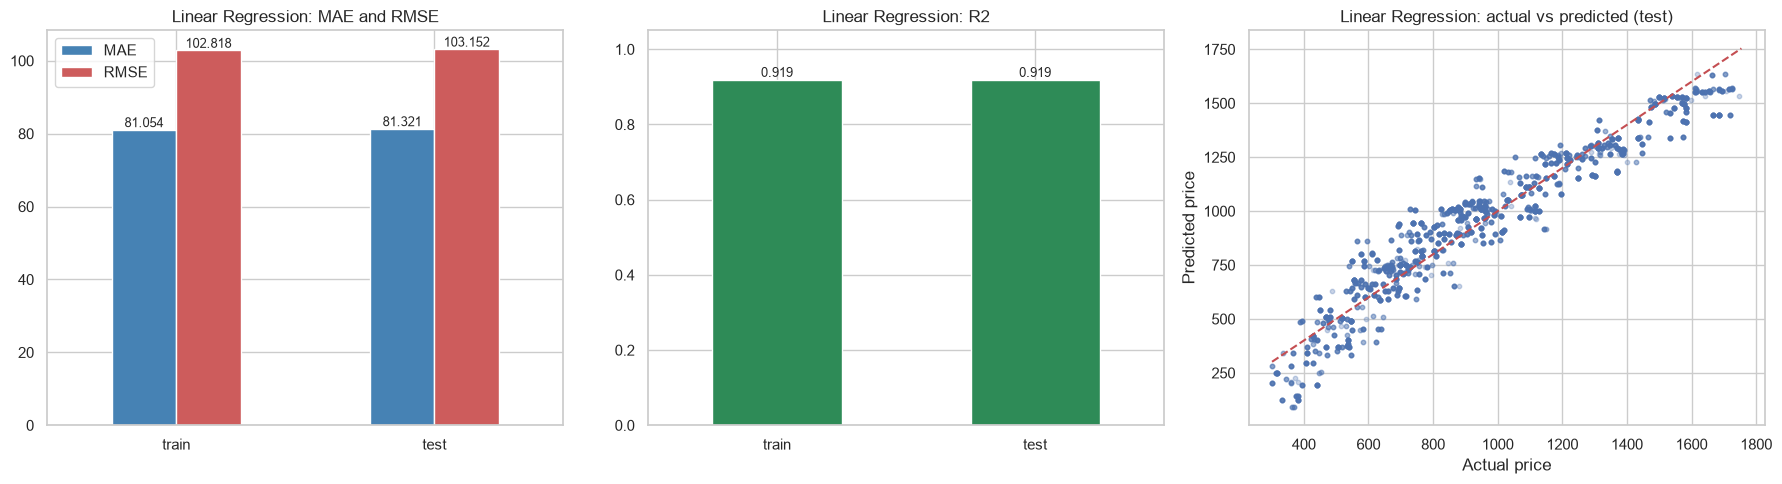

In [60]:
# Visualizing evaluation Metric Score chart
plot_scores("Linear Regression", lr_scores, lr_model)

Linear regression fits a straight line (a plane, with many inputs) that minimises the squared error between the predicted and the actual price. Each one-hot column gets its own coefficient, and distance and time get a price per km and per hour. It is the simplest model and a good baseline because the coefficients are easy to read.

On the test set it gets an MAE of 81.32, an RMSE of 103.15, an R2 of 0.9193 and a MAPE of 10.42%. The train scores are almost the same (RMSE 102.82), so it is not overfitting. In the actual vs predicted plot the points follow the diagonal but with a visible spread. The model cannot capture that the price per km depends on the class and the route at the same time (it would need interaction terms for that), so on average it is off by about 10%.

#### 2. Cross- Validation & Hyperparameter Tuning

Best params: {'model__alpha': 0.01}
Best CV RMSE: 102.83


,MAE,RMSE,R2,MAPE %
train,81.0536,102.8178,0.9194,10.3458
test,81.3206,103.1518,0.9193,10.4247


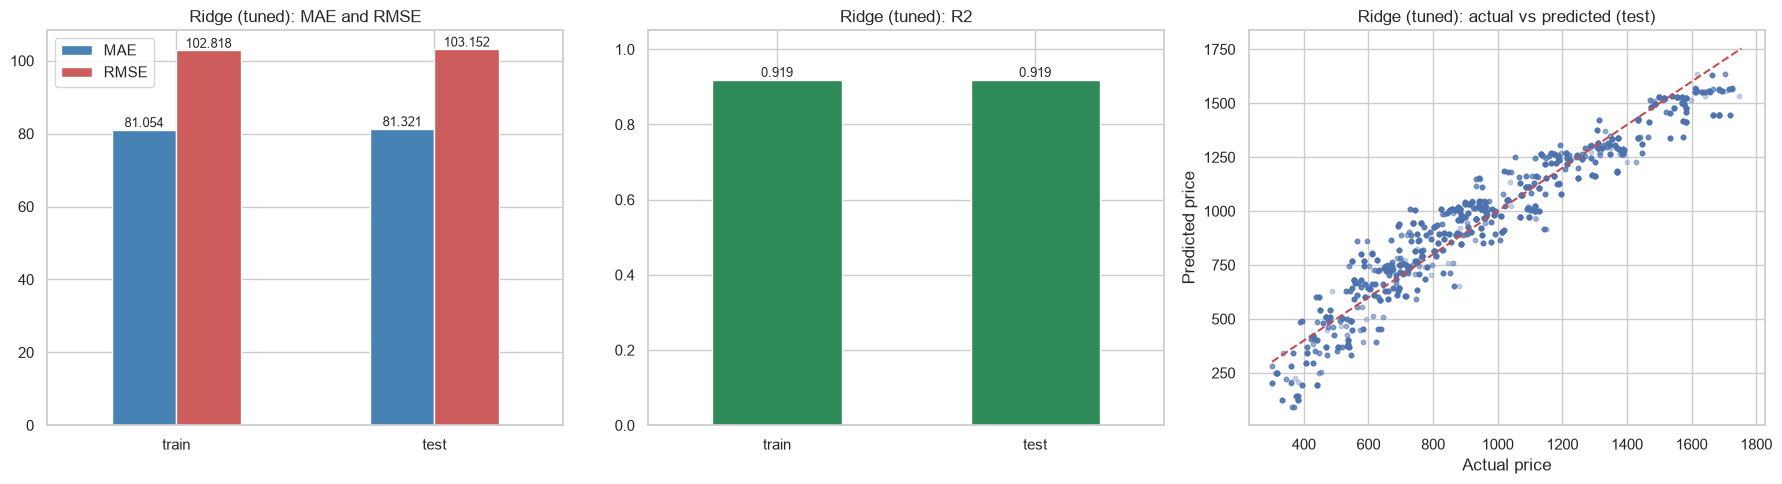

In [61]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
# plain linear regression has nothing to tune, so I use Ridge (linear regression with an L2 penalty)
# and search over the penalty strength with 5 fold cross validation
ridge_pipe = Pipeline([("prep", build_preprocessor()), ("model", Ridge())])
ridge_grid = GridSearchCV(
    ridge_pipe,
    param_grid={"model__alpha": [0.001, 0.01, 0.1, 1, 10, 100]},
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
    scoring="neg_root_mean_squared_error",
    n_jobs=-1,
)

# Fit the Algorithm
ridge_grid.fit(X_train, y_train)
print("Best params:", ridge_grid.best_params_)
print("Best CV RMSE:", round(-ridge_grid.best_score_, 3))

# Predict on the model
ridge_model = ridge_grid.best_estimator_
ridge_scores = evaluate("Ridge (tuned)", ridge_model)
display(ridge_scores)
plot_scores("Ridge (tuned)", ridge_scores, ridge_model)

##### Which hyperparameter optimization technique have you used and why?

Plain linear regression has no hyperparameters, so I switched to Ridge regression, which is linear regression with an L2 penalty, and used GridSearchCV over alpha (0.001 to 100) with 5 fold cross validation and RMSE as the score. Grid search made sense here because there is only one parameter with six values and the model trains in about a second, so trying every option is cheap.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

No real improvement. The best alpha was 0.01 with a cross validation RMSE of 102.83. On the test set the RMSE went from 103.1519 to 103.1518 and R2 stayed at 0.9193. This is expected: with 217,510 rows and only 26 inputs the linear model is not overfitting, so regularisation has nothing to fix. The limit of this model is its linear shape, not its settings.

### ML Model - 2 - Random Forest Regressor

In [62]:
# ML Model - 2 Implementation
rf_model = Pipeline([("prep", build_preprocessor()),
                     ("model", RandomForestRegressor(n_estimators=100, n_jobs=-1, random_state=RANDOM_STATE))])

# Fit the Algorithm
rf_model.fit(X_train, y_train)

# Predict on the model
rf_pred = rf_model.predict(X_test)
rf_scores = evaluate("Random Forest", rf_model)
rf_scores

,MAE,RMSE,R2,MAPE %
train,0.0,0.0,1.0,0.0
test,0.0,0.0,1.0,0.0


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

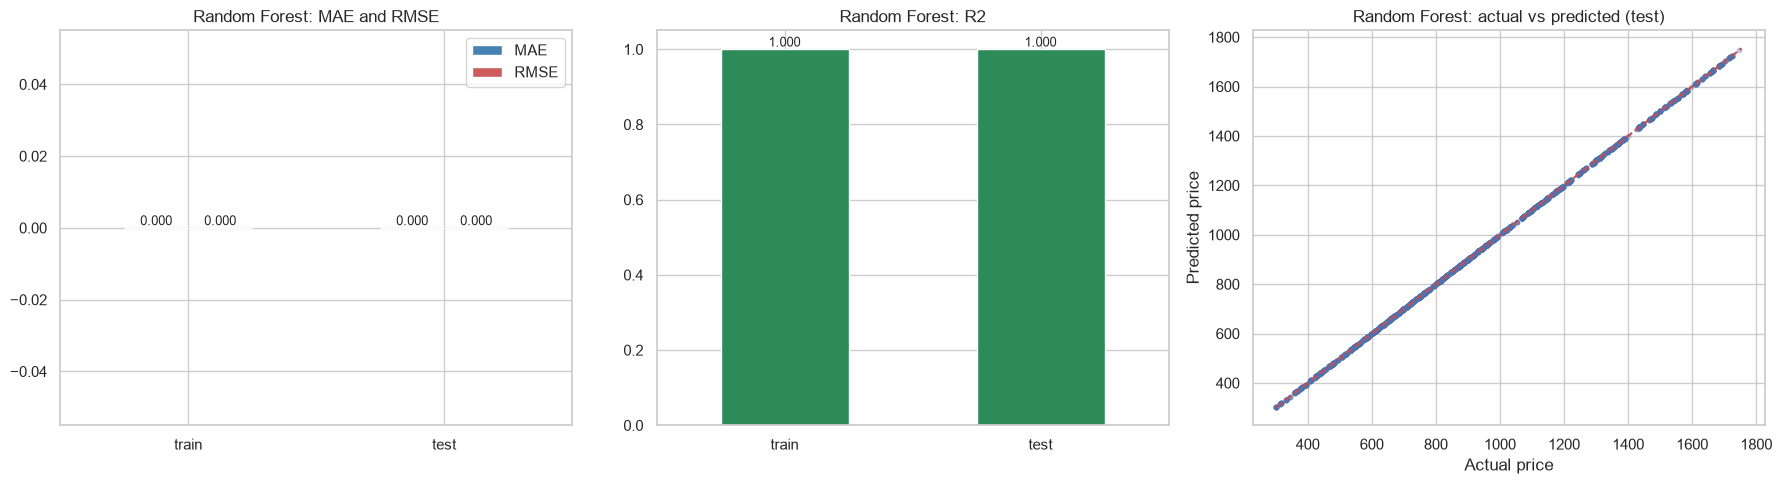

In [63]:
# Visualizing evaluation Metric Score chart
plot_scores("Random Forest", rf_scores, rf_model)

A random forest builds many decision trees, each on a random bootstrap sample of the rows and a random subset of the features, and averages their predictions. Each tree splits the data on conditions like "flightType is firstClass" or "distance > 600", so the forest can learn the interactions between class, route and agency without me creating them by hand.

The default forest (100 trees) gets an MAE, RMSE and MAPE of 0.0 and an R2 of 1.0 on both train and test. It looks too good at first, but it is correct. As shown in the wrangling step, there are only 490 route/class/agency combinations and each one always has the same price. Every combination in the test set also appears in the training set, so the trees learn the price list exactly. In the actual vs predicted plot all points sit on the diagonal.

#### 2. Cross- Validation & Hyperparameter Tuning

Best params: {'model__n_estimators': 100, 'model__min_samples_leaf': 1, 'model__max_features': 0.5, 'model__max_depth': None}
Best CV RMSE: 0.0002


,n_estimators,min_samples_leaf,max_features,max_depth,cv_rmse
6,100,1,0.5,NaN,0.0002
1,50,1,1.0,NaN,0.0004
8,100,2,1.0,NaN,0.0148
4,50,1,sqrt,NaN,0.0165
9,50,2,0.5,NaN,0.0194
2,100,2,sqrt,NaN,0.0469
7,100,5,0.5,20.0,0.7312
5,100,1,1.0,10.0,25.0408
3,100,2,1.0,10.0,25.0408
0,50,2,1.0,10.0,25.0806


,MAE,RMSE,R2,MAPE %
train,0.0,0.0,1.0,0.0
test,0.0,0.0,1.0,0.0


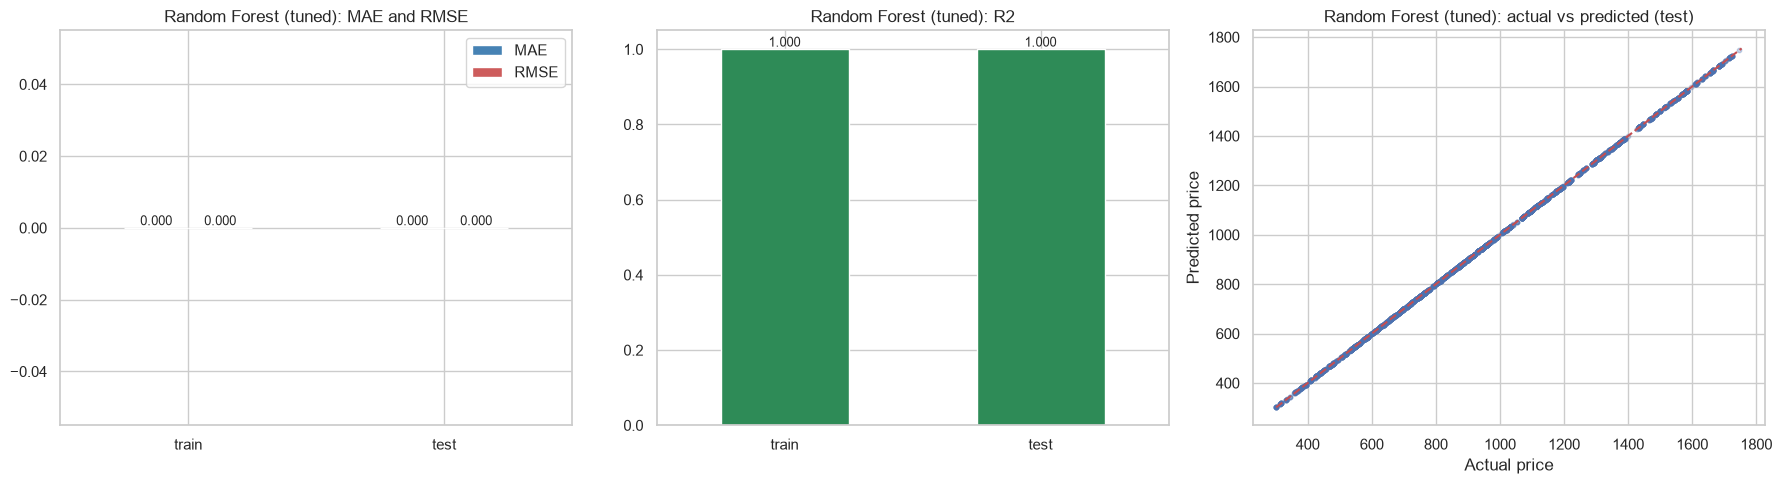

In [64]:
# ML Model - 2 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
# random search on a 40k row sample of the training data to keep the run time reasonable
tune_idx = X_train.sample(40000, random_state=RANDOM_STATE).index
rf_search = RandomizedSearchCV(
    Pipeline([("prep", build_preprocessor()),
              ("model", RandomForestRegressor(n_jobs=-1, random_state=RANDOM_STATE))]),
    param_distributions={
        "model__n_estimators": [50, 100, 200],
        "model__max_depth": [None, 10, 20],
        "model__min_samples_leaf": [1, 2, 5],
        "model__max_features": [1.0, 0.5, "sqrt"],
    },
    n_iter=10,
    cv=KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE,
    n_jobs=1,
)

# Fit the Algorithm
rf_search.fit(X_train.loc[tune_idx], y_train.loc[tune_idx])
print("Best params:", rf_search.best_params_)
print("Best CV RMSE:", round(-rf_search.best_score_, 4))
cv_table = pd.DataFrame(rf_search.cv_results_["params"])
cv_table.columns = [c.replace("model__", "") for c in cv_table.columns]
cv_table["cv_rmse"] = -rf_search.cv_results_["mean_test_score"]
display(cv_table.sort_values("cv_rmse").round(4))

# refit the best settings on the full training set
rf_best_params = {k.replace("model__", ""): v for k, v in rf_search.best_params_.items()}
rf_tuned = Pipeline([("prep", build_preprocessor()),
                     ("model", RandomForestRegressor(**rf_best_params, n_jobs=-1, random_state=RANDOM_STATE))])
rf_tuned.fit(X_train, y_train)

# Predict on the model
rf_tuned_scores = evaluate("Random Forest (tuned)", rf_tuned)
display(rf_tuned_scores)
plot_scores("Random Forest (tuned)", rf_tuned_scores, rf_tuned)

##### Which hyperparameter optimization technique have you used and why?

I used RandomizedSearchCV with 10 random combinations of n_estimators, max_depth, min_samples_leaf and max_features, with 3 fold cross validation on a 40,000 row sample of the training data. The full grid has 81 combinations and each forest takes a few seconds on 200,000 rows, so random search on a sample gives a good answer in much less time. After the search I refit the best settings on the full training set.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

On the random split there was nothing left to improve, since the default forest was already perfect. The best settings were 100 trees, min_samples_leaf = 1, max_depth = None and max_features = 0.5, with a CV RMSE of 0.0002, and the test RMSE stays at 0.0 with R2 = 1.0. The search table shows that the settings with max_depth = 10 were much worse (CV RMSE around 25), because trees that shallow cannot separate all 490 prices.

The tuning did help somewhere else. In the unseen route check further down, max_features = 0.5 raises R2 from 0.581 (default forest) to 0.709, because each split only sees half of the features, so the trees also learn from distance and class instead of only memorising the route.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

* **MAE** (mean absolute error) is the average amount a predicted price is off, in the same currency as the ticket. It is the easiest one to explain to the business: an MAE of 81 means a quote is off by about 81 on average, which a customer would notice.
* **RMSE** squares the errors before averaging, so it punishes big mistakes more. In pricing a few very wrong quotes hurt more than many small ones (a customer quoted 400 and charged 700 will not come back), so I used RMSE as the main metric for choosing models.
* **R2** shows how much of the variation in price the model explains. It is useful for comparing models, but harder for non technical people to read.
* **MAPE** gives the error as a percentage of the price, which is useful because an error of 80 means much more on a 300 ticket than on a 1,700 ticket.

For the business, the random forest means the platform can show the exact fare for any existing route, class and agency instantly. Customers can compare options faster, wrong quotes are avoided and the booking team does not have to look prices up by hand.

### ML Model - 3 - HistGradientBoosting Regressor

In [65]:
# ML Model - 3 Implementation
hgb_model = Pipeline([("prep", build_preprocessor()),
                      ("model", HistGradientBoostingRegressor(max_iter=300, learning_rate=0.1,
                                                              random_state=RANDOM_STATE))])

# Fit the Algorithm
hgb_model.fit(X_train, y_train)

# Predict on the model
hgb_pred = hgb_model.predict(X_test)
hgb_scores = evaluate("HistGradientBoosting", hgb_model)
hgb_scores

,MAE,RMSE,R2,MAPE %
train,2.0834,2.7171,0.9999,0.2600
test,2.0872,2.7218,0.9999,0.2605


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

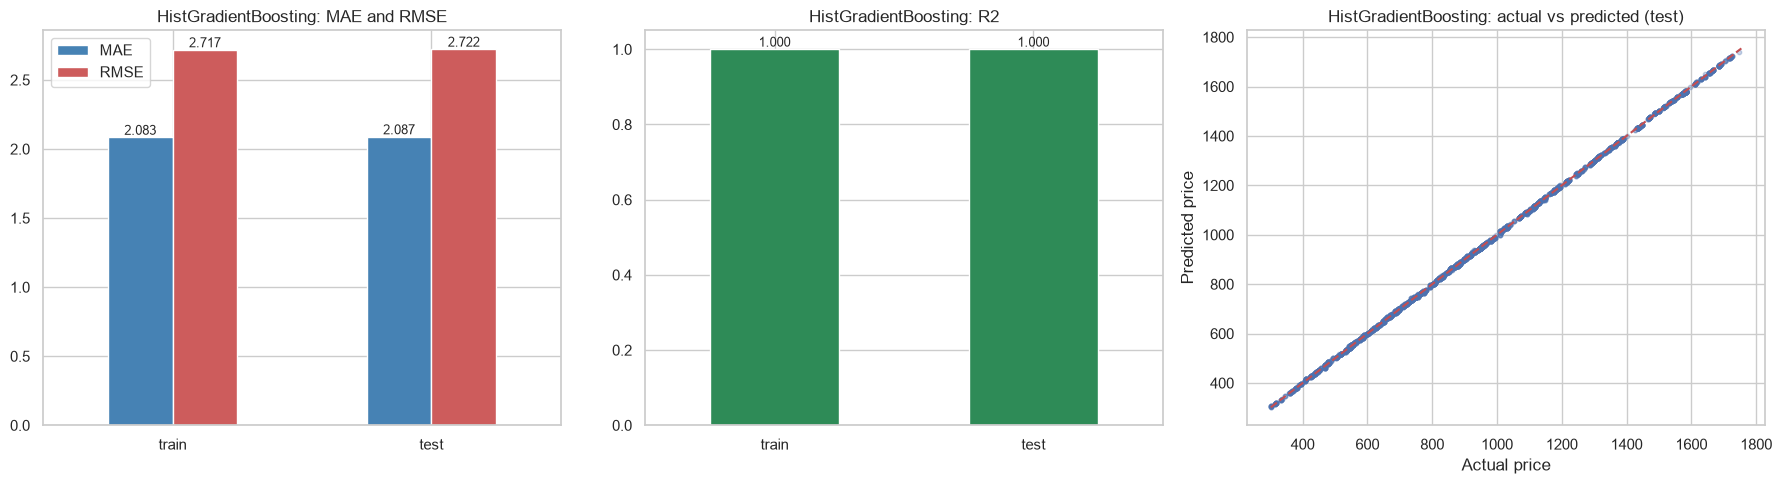

In [66]:
# Visualizing evaluation Metric Score chart
plot_scores("HistGradientBoosting", hgb_scores, hgb_model)

HistGradientBoosting is scikit-learn's fast gradient boosting model (similar to LightGBM). It first puts each numeric feature into bins, then builds trees one after another, where every new tree tries to fix the errors left by the earlier ones. It is usually one of the strongest models for tabular data and it trains quickly even on a few hundred thousand rows.

With 300 iterations and a learning rate of 0.1 it reaches an MAE of 2.09, an RMSE of 2.72, an R2 of 0.9999 and a MAPE of 0.26% on the test set, with the same numbers on train. It is almost as good as the random forest, just not exact, because boosting adds up many small steps and does not land precisely on every price.

#### 2. Cross- Validation & Hyperparameter Tuning

Best params: {'model__max_leaf_nodes': 63, 'model__max_iter': 500, 'model__max_depth': 6, 'model__learning_rate': 0.2, 'model__l2_regularization': 0.1}
Best CV RMSE: 0.0462


,MAE,RMSE,R2,MAPE %
train,0.0027,0.0037,1.0,0.0003
test,0.0027,0.0037,1.0,0.0003


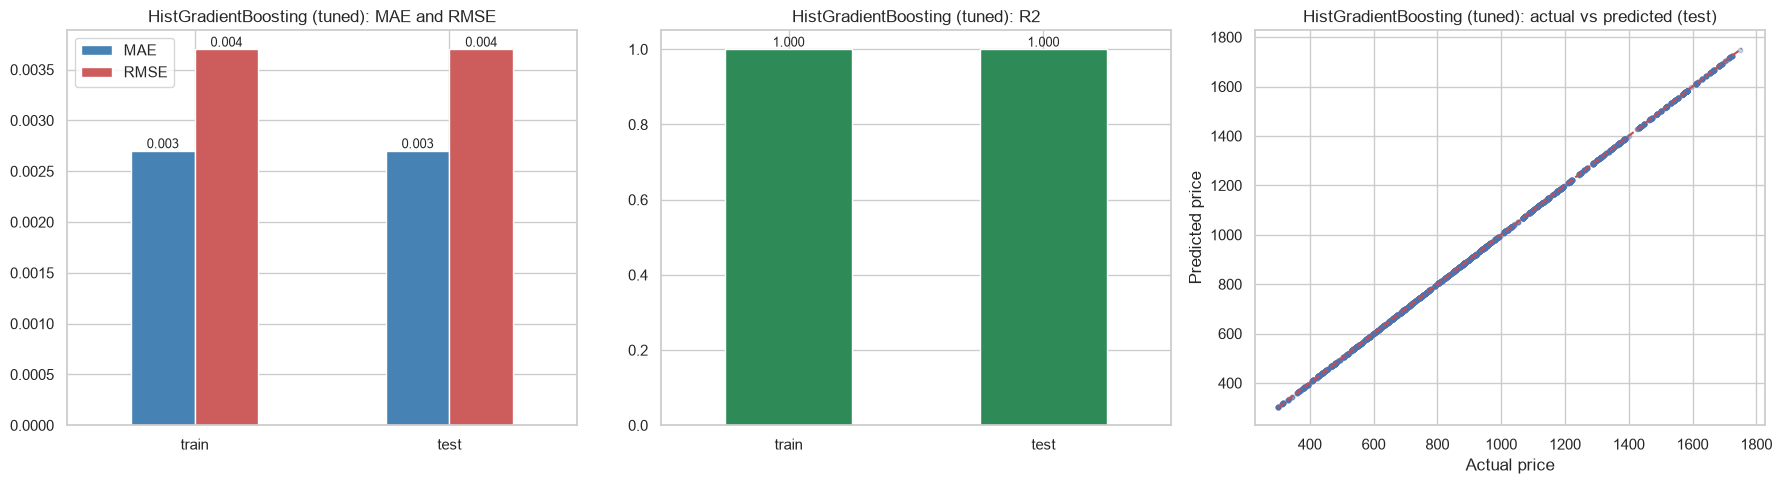

In [67]:
# ML Model - 3 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)
hgb_search = RandomizedSearchCV(
    Pipeline([("prep", build_preprocessor()),
              ("model", HistGradientBoostingRegressor(random_state=RANDOM_STATE))]),
    param_distributions={
        "model__learning_rate": [0.05, 0.1, 0.2],
        "model__max_iter": [200, 300, 500],
        "model__max_leaf_nodes": [15, 31, 63],
        "model__max_depth": [None, 6, 10],
        "model__l2_regularization": [0.0, 0.1, 1.0],
    },
    n_iter=12,
    cv=KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    scoring="neg_root_mean_squared_error",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

# Fit the Algorithm
hgb_search.fit(X_train.loc[tune_idx], y_train.loc[tune_idx])
print("Best params:", hgb_search.best_params_)
print("Best CV RMSE:", round(-hgb_search.best_score_, 4))

# refit on the full training set
hgb_best_params = {k.replace("model__", ""): v for k, v in hgb_search.best_params_.items()}
hgb_tuned = Pipeline([("prep", build_preprocessor()),
                      ("model", HistGradientBoostingRegressor(**hgb_best_params, random_state=RANDOM_STATE))])
hgb_tuned.fit(X_train, y_train)

# Predict on the model
hgb_tuned_scores = evaluate("HistGradientBoosting (tuned)", hgb_tuned)
display(hgb_tuned_scores)
plot_scores("HistGradientBoosting (tuned)", hgb_tuned_scores, hgb_tuned)

##### Which hyperparameter optimization technique have you used and why?

I used RandomizedSearchCV with 12 combinations over learning_rate, max_iter, max_leaf_nodes, max_depth and l2_regularization, with 3 fold cross validation on the same 40,000 row sample I used for the random forest. A full grid over five parameters would be 243 combinations, so random search covers the range much faster. The best settings were then refit on the full training set.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes, a big improvement. The best settings were learning_rate = 0.2, max_iter = 500, max_leaf_nodes = 63, max_depth = 6 and l2_regularization = 0.1 (CV RMSE 0.0462). On the test set the RMSE dropped from 2.72 to 0.0037 and the MAE from 2.09 to 0.0027, and R2 now rounds to 1.0. More trees, a higher learning rate and bigger trees let the model fit the price list almost exactly.

### Extra check: how do the models do on routes they have never seen?

The random split above has a weakness: every route in the test set was also in the training set, so the models only have to remember the price list. A harder question is what happens if the company starts selling a route the model has never seen.

To test this I used GroupKFold with 5 folds, where all flights of one route always stay in the same fold, so each test fold only has routes that were not used in training. The cities, classes and agencies are still known, only the route is new. I used a 60,000 row sample to keep it quick.

,RMSE (unseen routes),R2 (unseen routes)
model,,
Linear Regression,133.355,0.840
Ridge (tuned),133.237,0.840
Random Forest,192.169,0.581
Random Forest (tuned),162.926,0.709
HistGradientBoosting,156.387,0.717
HistGradientBoosting (tuned),161.619,0.717


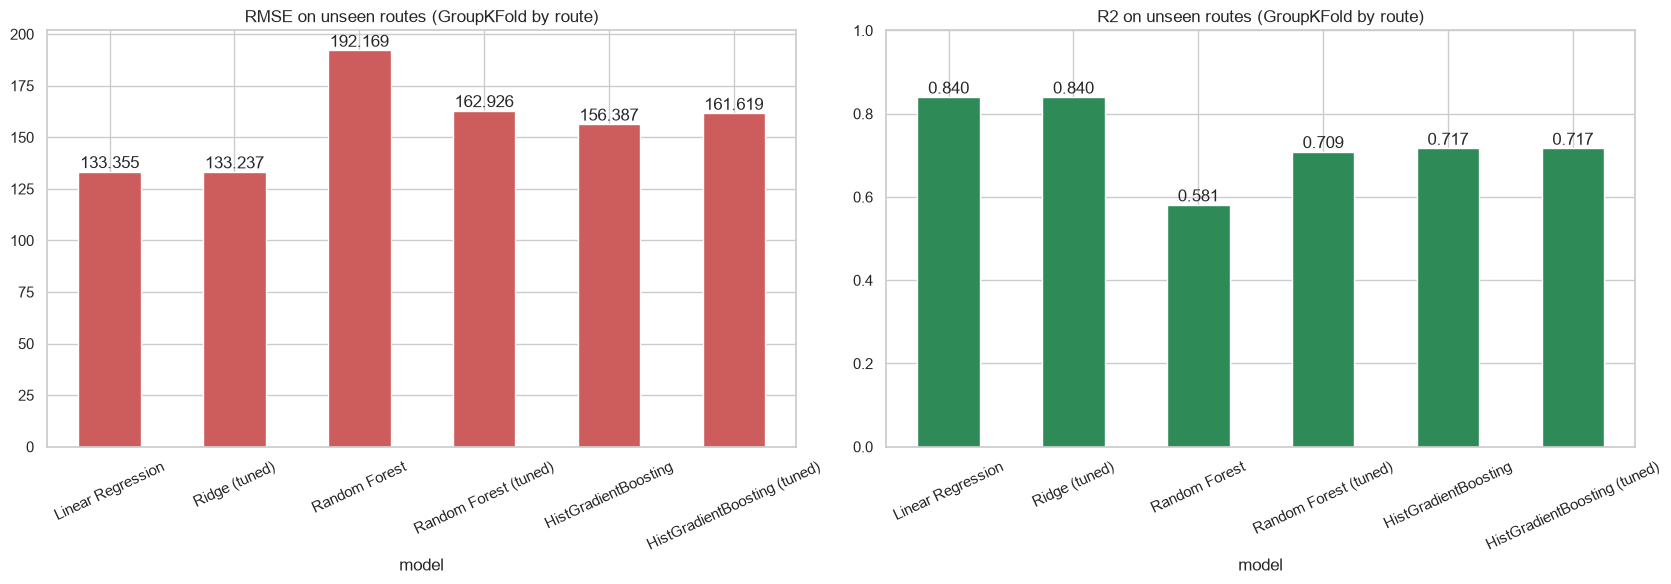

In [68]:
# GroupKFold keeps all flights of a route in the same fold, so the test fold only has unseen routes
gkf_sample = df.sample(60000, random_state=RANDOM_STATE)
gkf_models = {
    "Linear Regression": lr_model,
    "Ridge (tuned)": ridge_model,
    "Random Forest": rf_model,
    "Random Forest (tuned)": rf_tuned,
    "HistGradientBoosting": hgb_model,
    "HistGradientBoosting (tuned)": hgb_tuned,
}
gkf_rows = []
for name, model in gkf_models.items():
    cv = cross_validate(model, gkf_sample[FEATURES], gkf_sample[TARGET], groups=gkf_sample["route"],
                        cv=GroupKFold(n_splits=5), scoring=["neg_root_mean_squared_error", "r2"], n_jobs=1)
    gkf_rows.append({"model": name,
                     "RMSE (unseen routes)": -cv["test_neg_root_mean_squared_error"].mean(),
                     "R2 (unseen routes)": cv["test_r2"].mean()})
gkf_results = pd.DataFrame(gkf_rows).set_index("model").round(3)
display(gkf_results)

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
gkf_results["RMSE (unseen routes)"].plot(kind="bar", ax=axes[0], color="indianred", rot=25)
axes[0].set_title("RMSE on unseen routes (GroupKFold by route)")
gkf_results["R2 (unseen routes)"].plot(kind="bar", ax=axes[1], color="seagreen", rot=25)
axes[1].set_title("R2 on unseen routes (GroupKFold by route)")
axes[1].set_ylim(0, 1)
for ax in axes:
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2, p.get_height()),
                    ha="center", va="bottom")
plt.tight_layout()
plt.show()

The ranking flips on unseen routes. Linear regression is now the best, with an R2 of 0.840 (RMSE 133.4), and Ridge gives the same result. The default random forest falls to an R2 of 0.581 (RMSE 192.2), because it mostly memorised route specific prices and has nothing to remember for a new route. The tuned forest does better (R2 0.709, RMSE 162.9) thanks to max_features = 0.5, and gradient boosting is at 0.717 both before and after tuning.

What this tells me:

* For the routes the company already flies, the tree models are the right choice because they reproduce the price list exactly.
* For a brand new route, a simple linear model that relies on distance and class gives a more sensible first estimate than the trees.
* In practice the API only accepts the 70 known routes, and a new route will show up in the next batch of booking data. This is why the retraining DAG in Airflow matters: once a new route has some bookings, the forest is retrained and learns its price.

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

I mainly used RMSE, with MAE and MAPE to explain the results. RMSE is in the same units as the price and punishes large errors more, and large pricing errors are the ones that cost the business money and customer trust. MAE is the number I would give a manager (how far off a quote is on average), and MAPE shows the error as a percentage of the ticket price. R2 was useful to compare all the models on the same scale. I also looked at the RMSE and R2 on unseen routes (GroupKFold), because that shows how the model would behave when the business adds new routes.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

,MAE,RMSE,R2,MAPE %
Linear Regression,81.3214,103.1519,0.9193,10.4248
Ridge (tuned),81.3206,103.1518,0.9193,10.4247
Random Forest,0.0000,0.0000,1.0000,0.0000
Random Forest (tuned),0.0000,0.0000,1.0000,0.0000
HistGradientBoosting,2.0872,2.7218,0.9999,0.2605
HistGradientBoosting (tuned),0.0027,0.0037,1.0000,0.0003


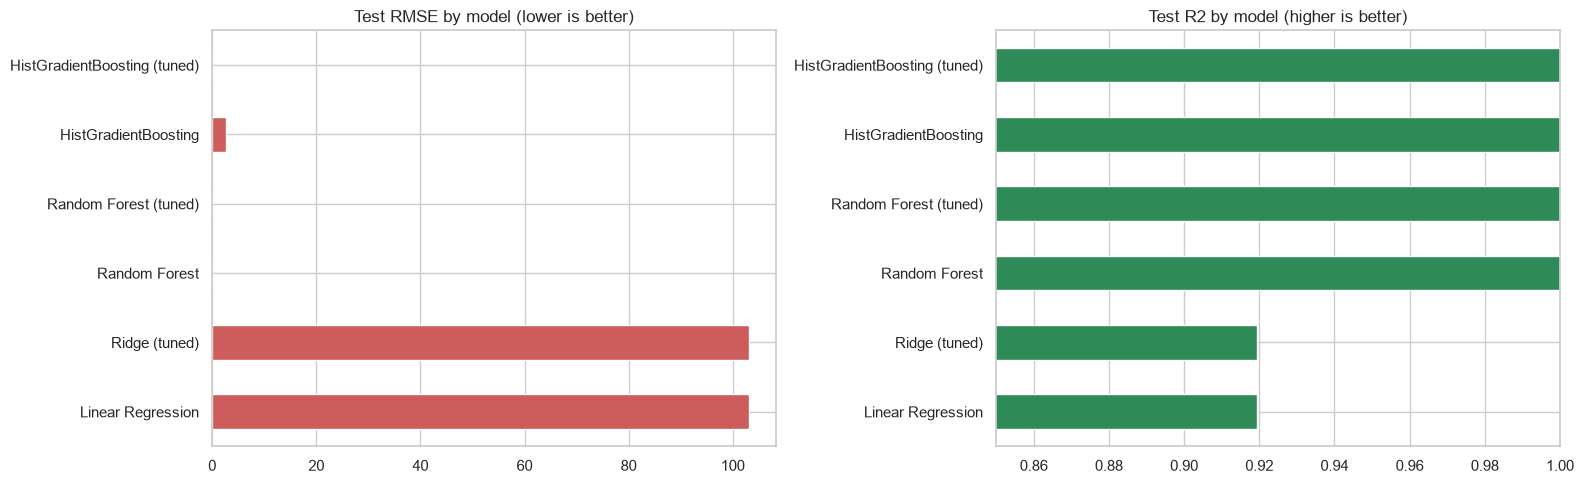

In [69]:
# all models side by side (random 80/20 split, test set)
comparison = pd.DataFrame(results).T.round(4)
display(comparison)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
comparison["RMSE"].plot(kind="barh", ax=axes[0], color="indianred")
axes[0].set_title("Test RMSE by model (lower is better)")
comparison["R2"].plot(kind="barh", ax=axes[1], color="seagreen")
axes[1].set_xlim(0.85, 1.0)
axes[1].set_title("Test R2 by model (higher is better)")
plt.tight_layout()
plt.show()

I chose the **tuned random forest** as the final model. On the test set it has the lowest RMSE of all six versions (practically 0, with R2 = 1.0). Tuned gradient boosting is very close (RMSE 0.0037) and linear regression is far behind (RMSE 103.15).

Between the two tree models I picked the random forest because it is exact, simple to tune, and its tuned settings also made it better on unseen routes than the default forest (0.709 vs 0.581). It is also the model that the training script in the repo (`src/flight_price/train.py`) picks on its own, because the script keeps the lowest RMSE. The weaker result on unseen routes is handled by the API only accepting known routes and by the retraining pipeline.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

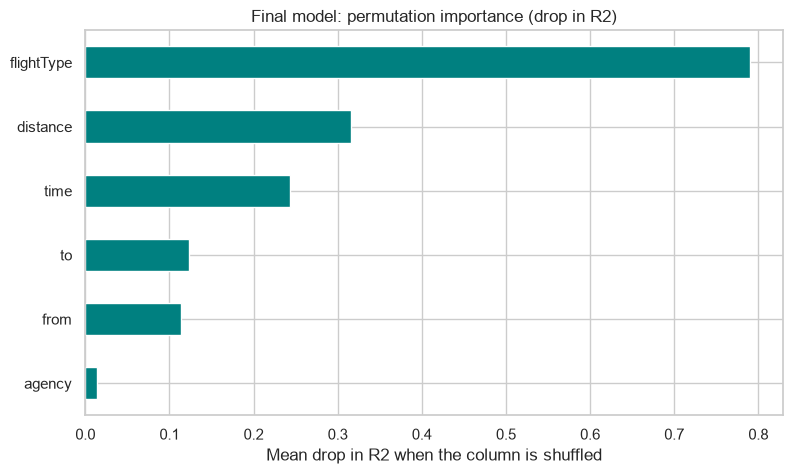

flightType    0.7896
distance      0.3161
time          0.2438
to            0.1228
from          0.1132
agency        0.0136
dtype: float64


In [70]:
# 1) permutation importance on the original input columns of the final model
final_model = rf_tuned
X_explain = X_test.sample(5000, random_state=RANDOM_STATE)
y_explain = y_test.loc[X_explain.index]
perm_final = permutation_importance(final_model, X_explain, y_explain, n_repeats=5,
                                    random_state=RANDOM_STATE, n_jobs=-1)
perm_series = pd.Series(perm_final.importances_mean, index=FEATURES).sort_values()
perm_series.plot(kind="barh", color="teal", figsize=(9, 5))
plt.title("Final model: permutation importance (drop in R2)")
plt.xlabel("Mean drop in R2 when the column is shuffled")
plt.show()
print(perm_series.sort_values(ascending=False).round(4))

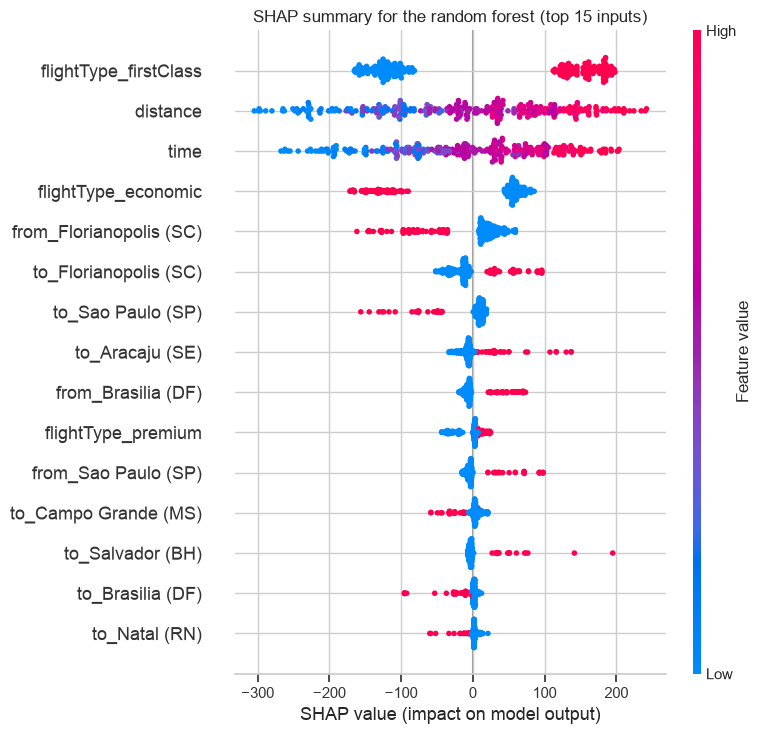

In [71]:
# 2) SHAP values for the random forest, on 300 test rows
prep = final_model.named_steps["prep"]
forest = final_model.named_steps["model"]
X_shap = pd.DataFrame(prep.transform(X_explain.head(300)), columns=prep.get_feature_names_out())
X_shap.columns = [c.replace("cat__", "").replace("remainder__", "") for c in X_shap.columns]

explainer = shap.TreeExplainer(forest)
shap_values = explainer.shap_values(X_shap, check_additivity=False)
shap.summary_plot(shap_values, X_shap, max_display=15, show=False)
plt.title("SHAP summary for the random forest (top 15 inputs)")
plt.tight_layout()
plt.show()

The random forest averages 100 decision trees. Each tree asks a series of yes/no questions about the flight (is it first class, is the distance above some value, does it leave from Florianopolis, and so on) and ends at a leaf that holds a price. Each tree sees a random sample of the rows and half of the features at every split, so the trees differ from each other and their average is stable.

I used two explainability tools:

* **Permutation importance** on 5,000 test rows shows how much R2 drops when one input is shuffled: flightType 0.79, distance 0.32, time 0.24, to 0.12, from 0.11 and agency 0.014.
* **SHAP** gives the same story for the one-hot columns. flightType_firstClass has the biggest effect: it adds roughly 100 to 200 to the price when the ticket is first class and takes away around 100 when it is not. Next come distance and time, where high values (red) push the price up and low values (blue) push it down. After that come specific cities, for example flying from Florianopolis lowers the price while flying to Florianopolis or Aracaju raises it, which matches the route heatmap in Chart 10. Agency hardly shows up, which agrees with hypothesis test 2.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [72]:
# Save the File
MODEL_DIR = "../models" if os.path.isdir("../models") else "."
MODEL_PATH = os.path.join(MODEL_DIR, "flight_price_model.joblib")

def file_md5(path):
    """md5 of the csv, used as a simple data version tag (same idea as in src/flight_price/train.py)."""
    if path.startswith("http"):
        data = urllib.request.urlopen(path).read()
    else:
        with open(path, "rb") as f:
            data = f.read()
    return hashlib.md5(data).hexdigest()

# distance and time are fixed per route, so the API only needs from/to and looks these up
route_table = flights.groupby(["from", "to"])[["distance", "time"]].first().reset_index()
routes_lookup = {f"{r['from']}|{r['to']}": {"distance": float(r["distance"]), "time": float(r["time"])}
                 for _, r in route_table.iterrows()}

final_scores = results["Random Forest (tuned)"]
bundle = {
    "pipeline": rf_tuned,
    "routes": routes_lookup,
    "allowed": {c: sorted(flights[c].unique().tolist()) for c in CATEGORICAL},
    "model_name": "random_forest",
    "metrics": {"rmse": float(final_scores["RMSE"]), "mae": float(final_scores["MAE"]), "r2": float(final_scores["R2"])},
    "trained_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "data_md5": file_md5(DATA_PATH + "flights.csv"),
}

try:
    joblib.dump(bundle, MODEL_PATH)
    print(f"Saved model bundle to {MODEL_PATH} ({os.path.getsize(MODEL_PATH) / 1e6:.1f} MB)")
except OSError as e:
    print("Could not save the model:", e)

Saved model bundle to ../models/flight_price_model.joblib (7.1 MB)


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [73]:
# Load the File and predict unseen data.
loaded = joblib.load(MODEL_PATH)
print("Loaded:", loaded["model_name"], "| trained at", loaded["trained_at"], "| metrics", loaded["metrics"])

# new requests the way the API would get them: only from, to, class and agency
new_requests = [
    {"from": "Recife (PE)", "to": "Florianopolis (SC)", "flightType": "firstClass", "agency": "FlyingDrops"},
    {"from": "Sao Paulo (SP)", "to": "Brasilia (DF)", "flightType": "economic", "agency": "CloudFy"},
    {"from": "Natal (RN)", "to": "Aracaju (SE)", "flightType": "premium", "agency": "Rainbow"},
]

def to_features(requests, bundle):
    rows = []
    for req in requests:
        key = f"{req['from']}|{req['to']}"
        if key not in bundle["routes"]:
            raise ValueError(f"unknown route {key}")
        rows.append({**req, **bundle["routes"][key]})
    return pd.DataFrame(rows)[FEATURES]

new_X = to_features(new_requests, loaded)
new_X["predicted_price"] = loaded["pipeline"].predict(new_X).round(2)

# compare with the real ticket price for the same route/class/agency
actual = flights.groupby(["from", "to", "flightType", "agency"])["price"].first()
new_X["actual_price"] = [actual.get((r["from"], r["to"], r["flightType"], r["agency"])) for _, r in new_X.iterrows()]
display(new_X)

# and a quick check on 5 random rows from the test set
check = X_test.sample(5, random_state=7).copy()
check["actual"] = y_test.loc[check.index]
check["predicted"] = loaded["pipeline"].predict(check[FEATURES]).round(2)
check

Loaded: random_forest | trained at 2026-10-26T08:42:00+00:00 | metrics {'rmse': 4.9177032941046715e-12, 'mae': 3.618001342347719e-12, 'r2': 1.0}


,from,to,flightType,agency,distance,time,predicted_price,actual_price
0,Recife (PE),Florianopolis (SC),firstClass,FlyingDrops,676.53,1.76,1434.38,1434.38
1,Sao Paulo (SP),Brasilia (DF),economic,CloudFy,257.81,0.67,389.47,389.47
2,Natal (RN),Aracaju (SE),premium,Rainbow,176.33,0.46,479.37,479.37


,from,to,flightType,agency,distance,time,actual,predicted
146619,Aracaju (SE),Sao Paulo (SP),firstClass,CloudFy,392.76,1.02,730.43,730.43
165886,Sao Paulo (SP),Brasilia (DF),premium,CloudFy,257.81,0.67,602.12,602.12
237943,Recife (PE),Florianopolis (SC),economic,CloudFy,676.53,1.76,761.20,761.20
35659,Natal (RN),Aracaju (SE),premium,Rainbow,176.33,0.46,479.37,479.37
263228,Florianopolis (SC),Aracaju (SE),economic,CloudFy,808.85,2.10,879.10,879.10


### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

* The flights data is clean (no missing values, no duplicates and no outliers), and the price of a ticket is fully set by its route, class and agency. There are 490 combinations and 490 unique prices.
* Flight class is the biggest driver of price, followed by distance. First class costs about 1.8 times economy on average (1,181 vs 658).
* Agencies charge the same within a class (Friedman p = 0.94), and the date, age, gender and company of the traveller do not change the price.
* Bookings have been falling every year since late 2019 while prices stayed flat. This is the main business concern from the EDA.
* Linear regression explains 91.9% of the variance (RMSE 103). The tuned random forest and tuned gradient boosting reproduce the prices almost perfectly on known routes, and I picked the random forest (RMSE close to 0, R2 = 1.0).
* On routes the model has never seen, linear regression generalises better (R2 0.84 vs 0.71 for the tuned forest). Because of this the API only accepts known routes, and the model gets retrained through Airflow as new data comes in.
* The final model is saved as `flight_price_model.joblib` together with a route lookup table. It is served by the Flask API, packaged with Docker, deployed on Kubernetes and tracked in MLflow, as described in the GitHub repo.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***